# Example 6.2 — Imatinib and approved ABL inhibitors: co-crystals, binding-site overlay and affinities

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:56:10Z
- **Contents:** 1 exchange · 8 tool calls · 2 figures

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/`, the figures in `figures/` and the 3D viewers of the binding-site overlays in `overlays/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/6.2-imatinib-abl-overlay-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 6.2-imatinib-abl-overlay-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 6.2-imatinib-abl-overlay-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/6.2-imatinib-abl-overlay-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 6.2-imatinib-abl-overlay-notebook-rerun.ipynb 6.2-imatinib-abl-overlay-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Look up imatinib and 3 close analog approved drugs in BindingDB, pull their ABL co-crystal structures with Ki/Kd data, then overlay the binding sites and visualize them with the affinity data.

In [ ]:
# Call 1 · search_compounds · ran 2026-11-24 04:56:00 UTC
await replay.call(1, 'search_compounds', {'query': 'imatinib', 'limit': 5},
                  sha256='1f2a50bf819de48009ec8144d0b21eef4aca07d81ee80cd8718d9c5f2d42211d')

**Call 1** · `search_compounds` · recorded result · sha256 `1f2a50bf819d…`

_3 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 13530 | BDBM13530 | Gleevec | KTUFNOKKBVMGRW-UHFFFAOYSA-N | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 493.26 | 1156 | 459 | Imatinib |
| 31341 | BDBM31341 | IMATINIB | KTUFNOKKBVMGRW-UHFFFAOYSA-N | Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C |  | 0 | 0 | IMATINIB |
| 50434581 | BDBM50434581 | imatinib-CD3 | KTUFNOKKBVMGRW-BMSJAHLVSA-N | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.58 | 2 | 2 | imatinib-CD3 |


In [ ]:
# Call 2 · search_compounds · ran 2026-11-24 04:56:00 UTC
await replay.call(2, 'search_compounds', {'query': 'nilotinib', 'limit': 5},
                  sha256='ac3861dbb71b53628fbe24fbba2020f6f21474b63a1d04bda6bbd311c2e49fa5')

**Call 2** · `search_compounds` · recorded result · sha256 `ac3861dbb71b…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50237710 | BDBM50237710 | NILOTINIB | HHZIURLSWUIHRB-UHFFFAOYSA-N | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F | 529.18 | 614 | 409 | NILOTINIB |


In [ ]:
# Call 3 · search_compounds · ran 2026-11-24 04:56:00 UTC
await replay.call(3, 'search_compounds', {'query': 'dasatinib', 'limit': 5},
                  sha256='c2cafab76a6e5d58117c3604b0c6e86d38d60a74b3f9c97851d6515e41069671')

**Call 3** · `search_compounds` · recorded result · sha256 `c2cafab76a6e…`

_3 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 13216 | BDBM13216 | DASATINIB | ZBNZXTGUTAYRHI-UHFFFAOYSA-N | Cc1cccc(c1NC(=O)c2cnc(s2)Nc3cc(nc(n3)C)N4CCN(CC4)CCO)Cl | 487.16 | 1226 | 443 | DASATINIB |
| 31089 | BDBM31089 | DASATINIB | ZBNZXTGUTAYRHI-UHFFFAOYSA-N | Cc1cccc(c1NC(=O)c2cnc(s2)Nc3cc(nc(n3)C)N4CCN(CC4)CCO)Cl | 487.16 | 16 | 11 | DASATINIB |
| 82130 | BDBM82130 | Dasatinib | JGPNDAHBLOQVAU-UHFFFAOYSA-N | Cc1nc(cc(n1)N1CCN(CCO)CC1)N=C1NCC(S1)C(=O)Nc1c(C)cccc1Cl \|w:16.17\| | 489.17 | 3 | 3 | Dasatinib |


In [ ]:
# Call 4 · search_compounds · ran 2026-11-24 04:56:00 UTC
await replay.call(4, 'search_compounds', {'query': 'bosutinib', 'limit': 5},
                  sha256='f9bd0555ee77379f8f29ab5dfd7aab7bde82736a25a42f2d74b6a1081a9a4761')

**Call 4** · `search_compounds` · recorded result · sha256 `f9bd0555ee77…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 4552 | BDBM4552 | BOSUTINIB | UBPYILGKFZZVDX-UHFFFAOYSA-N | CN1CCN(CC1)CCCOc2cc3c(cc2OC)c(c(cn3)C#N)Nc4cc(c(cc4Cl)Cl)OC | 529.16 | 585 | 386 | BOSUTINIB |


In [ ]:
# Call 5 · search_compounds · ran 2026-11-24 04:56:00 UTC
await replay.call(5, 'search_compounds', {'query': 'ponatinib', 'limit': 5},
                  sha256='6bb36fd77575ae716991e8724bf90614c004d00c81e2f23431df9191f8e2ad15')

**Call 5** · `search_compounds` · recorded result · sha256 `6bb36fd77575…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50322535 | BDBM50322535 | PONATINIB | PHXJVRSECIGDHY-UHFFFAOYSA-N | Cc1ccc(cc1C#Cc2cnc3n2nccc3)C(=O)Nc4ccc(c(c4)C(F)(F)F)CN5CCN(CC5)C | 532.559 | 153 | 53 | PONATINIB |


In [ ]:
# Call 6 · find_pdb_complexes · ran 2026-11-24 04:56:00 UTC
await replay.call(6, 'find_pdb_complexes', {'uniprot': 'P00519', 'limit': 100},
                  sha256='13a21b4483af763cc37f30d4b4a1c3e73e0abee3f2a9b0abf782bef344e26e8a')

**Call 6** · `find_pdb_complexes` · recorded result · sha256 `13a21b4483af…` · uses RCSB, whose answers can change

```json
{
  "target": "P00519",
  "n_compounds": 27,
  "note": "98 more compound(s) have PDB entries that BindingDB links to other proteins or to other records of this protein (e.g. another strain or construct); pass only_linked=false to list them. overlay_binding_site checks each chain against the target's sequence."
}
```

_27 rows_

| monomerid | bdbm | name | ligand_code | match | pdb_ids | n_pdb_ids | affinity_type | median_nm | best_nm | n_measurements | other_affinity_types | found_in_pdb_by_inchikey |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 4552 | BDBM4552 | BOSUTINIB | DB8 | record | 3UE4 | 1 | Kd | 0.062 | 0.029 | 15 | IC50 |  |
| 50459091 | BDBM50459091 | Asciminib | AY7 | same structure | 5MO4, 8SSN | 2 | Kd | 0.5 | 0.5 | 1 | IC50 | 5MO4, 8SSN |
| 13216 | BDBM13216 | DASATINIB | 1N1 | record | 2GQG, 4XEY, 4XLI, 7N9G | 4 | Kd | 0.53 | 0.016 | 28 | IC50 |  |
| 6568 | BDBM6568 | PD173955 | P17 | record | 1M52 | 1 | Kd | 1.35 | 0.52 | 16 | IC50, Ki |  |
| 13534 | BDBM13534 | VX680 | VX6 | same structure | 2F4J, 4ZOG | 2 | Kd | 9.4 | 3 | 27 | IC50, Ki | 2F4J, 4ZOG |
| 50237710 | BDBM50237710 | NILOTINIB | NIL | same structure | 3CS9, 5MO4 | 2 | Kd | 13.5 | 3.6 | 16 | IC50, Ki | 3CS9, 5MO4 |
| 13530 | BDBM13530 | Gleevec | STI | same structure | 1IEP, 1OPJ, 2HYY, 3GVU, 3K5V, 3MS9, 3MSS, 3PYY, 6HD4, 6HD6, 6NPE, 6NPU, 6NPV, 7N9G | 14 | Kd | 35 | 1 | 32 | EC50, IC50, Ki |  |
| 25117 | BDBM25117 | AXITINIB | AXI | record | 4TWP, 4WA9 | 2 | Kd | 84 | 1.5 | 15 | IC50 |  |
| 50459086 | BDBM50459086 | CHEMBL4217428 | FYH | record | 6HD6 | 1 | Kd | 2000 | 2000 | 1 | IC50 |  |
| 50459087 | BDBM50459087 | CHEMBL1234477 | MS9 | record | 3MS9 | 1 | Kd | 6000 | 6000 | 1 |  |  |
| 50322535 | BDBM50322535 | PONATINIB | 0LI | record | 3IK3, 3OXZ | 2 | IC50 | 0.37 | 0.3 | 24 |  |  |
| 185674 | BDBM185674 | Rebastinib | 919 | same structure | 3QRI, 3QRJ | 2 | IC50 | 1.7 | 0.75 | 14 |  | 3QRI, 3QRJ |
| 50345584 | BDBM50345584 | 5-((5-(4-((4-(2-hydroxyethyl)piperazin-1-yl)methyl)-3-(trifluoromethyl)phenylcarbamoyl)-2-methylphenyl)ethynyl)-1-methyl-1H-imidazole-2-carboxamide | XY3 | record | 3OY3 | 1 | IC50 | 3.6 | 3.6 | 1 |  |  |
| 3085 | BDBM3085 | PD166326 | P16 | record | 1OPK, 1OPL, 2FO0, 2G2H | 4 | IC50 | 5.4 | 2.8 | 2 |  |  |
| 12985 | BDBM12985 | 5-Amido-pyrrolopyrazole 9d | 627 | same structure | 2V7A | 1 | IC50 | 7.9 | 7.9 | 1 |  |  |
| 50208747 | BDBM50208747 | (R)-4-((3-(dimethylamino)pyrrolidin-1-yl)methyl)-N-(4-methyl-3-(4-(pyrimidin-5-yl)pyrimidin-2-ylamino)phenyl)-3-(trifluoromethyl)benzamide hydrochloride | 406 | connectivity only | 2E2B | 1 | IC50 | 12 | 12 | 1 |  | 2E2B |
| 50590367 | BDBM50590367 | CHEMBL384575 | 627 | connectivity only | 2V7A | 1 | IC50 | 25 | 25 | 1 |  |  |
| 50178612 | BDBM50178612 | N-\[3-(4,5'-BIPYRIMIDIN-2-YLAMINO)-4-METHYLPHENYL\]-4-{\[(3S)-3-(DIMETHYLAMINO)PYRROLIDIN-1-YL\]METHYL}-3-(TRIFLUOROMETHYL)BENZAMIDE | 406 | same structure | 2E2B | 1 | IC50 | 26 | 26 | 1 |  | 2E2B |
| 50004205 | BDBM50004205 | TOZASERTIB | VX6 | same structure | 2F4J, 4ZOG | 2 | IC50 | 46 | 46 | 1 |  | 2F4J, 4ZOG |
| 50530294 | BDBM50530294 | CHEMBL4538292 | KWP | connectivity only | 6NPV | 1 | IC50 | 129 | 100 | 4 | EC50 | 6NPV |
| 50434581 | BDBM50434581 | imatinib-CD3 | STI | connectivity only | 1IEP, 1OPJ, 2HYY, 3GVU, 3K5V, 3MS9, 3MSS, 3PYY, 6HD4, 6HD6, 6NPE, 6NPU, 6NPV, 7N9G | 14 | IC50 | 223 | 223 | 1 |  |  |
| 66241 | BDBM66241 | MLS000036279 | 3YY | connectivity only | 3PYY | 1 | IC50 | 324.5 | 251 | 4 | EC50 | 3PYY |
| 50530307 | BDBM50530307 | CHEMBL4471351 | KWV | record | 6NPU | 1 | IC50 | 357 | 316 | 4 | EC50 |  |
| 50652932 | BDBM50652932 | CHEMBL1738759 | 9DP | same structure | 3QRK | 1 | IC50 | 415 | 57 | 2 |  | 3QRK |
| 50325999 | BDBM50325999 | 3-(6-(4-(trifluoromethoxy)phenylamino)pyrimidin-4-yl)benzamide | STJ | record | 3K5V | 1 | IC50 | 604 | 9 | 4 |  |  |
| 86734 | BDBM86734 | Gleevec | STI | same structure | 1IEP, 1OPJ, 2HYY, 3GVU, 3K5V, 3MS9, 3MSS, 3PYY, 6HD4, 6HD6, 6NPE, 6NPU, 6NPV, 7N9G | 14 | IC50 | 825 | 75 | 31 |  |  |
| 50530275 | BDBM50530275 | CHEMBL4562851 | KWD | same structure | 6NPE | 1 | IC50 | 880 | 501 | 4 | EC50 | 6NPE |


In [ ]:
# Call 7 · similarity_search · ran 2026-11-24 04:56:09 UTC
arguments = {
    'smiles': 'CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1',
    'threshold': 0.3,
    'limit': 2000,
}
await replay.call(7, 'similarity_search', arguments,
                  sha256='5f2f12e60b0b0f6e5a14b8eb59b2159f25fd3f3446c82de849976447f0c615f4')

**Call 7** · `similarity_search` · recorded result · sha256 `5f2f12e60b0b…`

| name | smiles |
| --- | --- |
| query | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1 |

```json
{
  "query": {
    "input": "CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1",
    "canonical": "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1",
    "threshold": 0.3,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 7624,
  "compounds_searched": 1466457,
  "search_set_size": 1466457
}
```

_500 rows, truncated at the limit_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets | similarity |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 13530 | BDBM13530 | Gleevec | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 493.26 | 1156 | 459 | 1 |
| 86734 | BDBM86734 | Gleevec | Cc3ccc(NC(=O)c2ccc(CN1CCN(C)CC1)cc2)cc3Nc5nccc(c4cccnc4)n5 | 493.26 | 66 | 10 | 1 |
| 31341 | BDBM31341 | IMATINIB | Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C |  | 0 | 0 | 1 |
| 612739 | BDBM612739 | US11725005, Compound 101 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccnc3)c2)CC1 | 570.29 | 3 | 3 | 0.929 |
| 50434581 | BDBM50434581 | imatinib-CD3 | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.58 | 2 | 2 | 0.9 |
| 50634633 | BDBM50634633 |  | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.28 | 2 | 1 | 0.9 |
| 50444657 | BDBM50444657 | CHEMBL3098615 | Cc1ccc(NC(=O)c2ccc(CN3CCN(CCO)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 523.63 | 1 | 1 | 0.886 |
| 50444658 | BDBM50444658 | CHEMBL3098616 | Cc1ccc(NC(=O)c2ccc(CN3CCN(CCF)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 525.62 | 1 | 1 | 0.873 |
| 50444656 | BDBM50444656 | CHEMBL3098614 | Cc1ccc(NC(=O)c2ccc(CN3CCN(Cc4ccc(I)cc4)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 695.6 | 1 | 1 | 0.871 |
| 612799 | BDBM612799 | US11725005, Compound 309 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccc3)c2)CC1 | 569.29 | 3 | 3 | 0.861 |
| 50434582 | BDBM50434582 | CHEMBL2386594 | Cc1ccc(NC(=O)c2ccc(CN3CCNCC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 575.68 | 5 | 2 | 0.845 |
| 50313640 | BDBM50313640 | N-(4-methyl-3-(4-(6-methylpyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3ccc(C)nc3)c2)CC1 | 507.629 | 2 | 2 | 0.843 |
| 612807 | BDBM612807 | US11725005, Compound 401 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccc(C)c3)c2)CC1 | 583.31 | 3 | 3 | 0.827 |
| 612740 | BDBM612740 | US11725005, Compound 102 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccn3)c2)CC1 | 570.29 | 3 | 3 | 0.824 |
| 50432866 | BDBM50432866 | CHEMBL382605 | CN1CCN(Cc2ccc(cc2Cl)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 528.05 | 1 | 1 | 0.824 |
| 481130 | BDBM481130 | US10906896, Cpd 830 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ccn3)c2)CC1 | 584.3 | 6 | 3 | 0.822 |
| 612741 | BDBM612741 | US11725005, Compound 103 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccncc3)c2)CC1 | 570.29 | 3 | 3 | 0.822 |
| 50290422 | BDBM50290422 | 4-(4-Methyl-piperazin-1-ylmethyl)-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2cccc(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 479.576 | 12 | 11 | 0.812 |
| 481131 | BDBM481131 | US10906896, Cpd 832 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccn(C)n3)c2)CC1 | 573.3 | 9 | 3 | 0.811 |
| 612811 | BDBM612811 | US11725005, Compound 402 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccc(C)cc3)c2)CC1 | 583.31 | 3 | 3 | 0.811 |
| 481146 | BDBM481146 | US10906896, Cpd 8300 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccn(C)n3)c2)CC1 |  | 0 | 0 | 0.811 |
| 481129 | BDBM481129 | US10906896, Cpd 820 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccc(C)cn3)c2)CC1 | 584.3 | 6 | 3 | 0.8 |
| 50178611 | BDBM50178611 | 3-bromo-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2Br)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 571.17 | 3 | 3 | 0.8 |
| 50178617 | BDBM50178617 | 3-fluoro-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 511.25 | 3 | 3 | 0.8 |
| 50432865 | BDBM50432865 | CHEMBL203071 | CN1CCN(Cc2ccc(cc2I)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 619.5 | 1 | 1 | 0.8 |
| 612798 | BDBM612798 | US11725005, Compound 305 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)N3CCCC3)c2)CC1 | 562.32 | 3 | 3 | 0.789 |
| 612893 | BDBM612893 | US11725005, Compound 8300 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnn(C)c3)c2)CC1 | 573.3 | 3 | 3 | 0.789 |
| 612837 | BDBM612837 | US11725005, Compound 404 | COc1cccc(c1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)n1 | 599.3 | 3 | 3 | 0.785 |
| 481104 | BDBM481104 | US10906896, Cpd 101 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cccnc4)C3)c2)n1 | 679.31 | 3 | 3 | 0.78 |
| 481135 | BDBM481135 | BDBM481139 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccns3)c2)CC1 | 576.24 | 9 | 3 | 0.779 |
| 481143 | BDBM481143 | US10906896, Cpd 8270 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nccs3)c2)CC1 | 576.24 | 6 | 3 | 0.779 |
| 481144 | BDBM481144 | US10906896, Cpd 8280 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ncc(C)s3)c2)CC1 | 590.26 | 6 | 3 | 0.779 |
| 612764 | BDBM612764 | US11725005, Compound 107 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3ccn\[nH\]3)c2)n1 | 559.28 | 3 | 3 | 0.779 |
| 612767 | BDBM612767 | US11725005, Compound 108 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3\[nH\]ncc3C)c2)n1 | 573.3 | 3 | 3 | 0.779 |
| 612784 | BDBM612784 | US11725005, Compound 118 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cn\[nH\]c3)c2)n1 | 559.28 | 3 | 3 | 0.779 |
| 612785 | BDBM612785 | US11725005, Compound 119 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cn\[nH\]c3C)c2)n1 | 573.3 | 3 | 3 | 0.779 |
| 612786 | BDBM612786 | US11725005, Compound 201 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ncco3)c2)CC1 | 560.26 | 3 | 3 | 0.779 |
| 481139 | BDBM481139 | US10906896, Cpd 8230 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccns3)c2)CC1 |  | 0 | 0 | 0.779 |
| 612796 | BDBM612796 | US11725005, Compound 303 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-n3cccn3)c2)CC1 | 559.28 | 3 | 3 | 0.772 |
| 481128 | BDBM481128 | US10906896, Cpd 809 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3oncc3C)c2)CC1 | 574.28 | 6 | 3 | 0.769 |
| 481136 | BDBM481136 | US10906896, Cpd 8180 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3sncc3C)c2)CC1 | 590.26 | 6 | 3 | 0.769 |
| 481138 | BDBM481138 | US10906896, Cpd 8200 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnsc3)c2)CC1 | 576.24 | 6 | 3 | 0.769 |
| 612772 | BDBM612772 | US11725005, Compound 113 | Cc1cc(-c2cncc(-c3ccnc(Nc4cc(NC(=O)c5ccc(CN6CCN(C)CC6)cc5)ccc4C)n3)c2)\[nH\]n1 | 573.3 | 6 | 3 | 0.769 |
| 612841 | BDBM612841 | US11725005, Compound 405 | COc1ccc(cc1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)n1 | 599.3 | 3 | 3 | 0.769 |
| 50178615 | BDBM50178615 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)-3-(trifluoromethyl)benzamide | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 561.25 | 3 | 3 | 0.769 |
| 50341234 | BDBM50341234 | 4-(chloromethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 429.14 | 3 | 3 | 0.768 |
| 481134 | BDBM481134 | US10906896, Cpd 8130 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnc(C)o3)c2)CC1 | 575.28 | 6 | 3 | 0.759 |
| 481137 | BDBM481137 | US10906896, Cpd 8190 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ns3)c2)CC1 | 590.26 | 6 | 3 | 0.759 |
| 481142 | BDBM481142 | US10906896, Cpd 8260 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnc(C)s3)c2)CC1 | 591.25 | 6 | 3 | 0.759 |
| 481145 | BDBM481145 | US10906896, Cpd 8290 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(C)cs3)c2)CC1 | 590.26 | 6 | 3 | 0.759 |
| 612789 | BDBM612789 | US11725005, Compound 202 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(C)co3)c2)CC1 | 574.28 | 3 | 3 | 0.759 |
| 612791 | BDBM612791 | US11725005, Compound 207 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)no3)c2)CC1 | 574.28 | 3 | 3 | 0.759 |
| 612865 | BDBM612865 | US11725005, Compound 8230 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnns3)c2)CC1 | 577.24 | 3 | 3 | 0.759 |
| 106568 | BDBM106568 | US8586600, II-8 | Cc1ccc(NC(=O)c2ccc(CN3C(=O)C=CC3=O)cc2)cc1Nc1nccc(n1)-c1cccnc1 \|c:16\| | 490.18 | 1 | 1 | 0.753 |
| 481133 | BDBM481133 | US10906896, Cpd 8120 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnco3)c2)CC1 | 561.26 | 6 | 3 | 0.75 |
| 481140 | BDBM481140 | US10906896, Cpd 8240 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3snnc3C)c2)CC1 | 591.25 | 6 | 3 | 0.75 |
| 481141 | BDBM481141 | US10906896, Cpd 8250 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nncs3)c2)CC1 | 577.24 | 6 | 3 | 0.75 |
| 50355495 | BDBM50355495 | CHEMBL1908391 | Cc1ccc(cc1Nc2nc(cs2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C | 498.22 | 452 | 378 | 0.747 |
| 50599045 | BDBM50599045 | CHEMBL5207077 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(Nc4nccc(n4)-c4cccnc4)c3)cc2C(F)(F)F)CC1 | 561.61 | 2 | 1 | 0.747 |
| 734447 | BDBM734447 | US20250129067, Compound Masitinib | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nc(-c2cccnc2)cs1 | 498.22 | 1 | 1 | 0.747 |
| 50341235 | BDBM50341235 | 4-(aminomethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CN)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 410.19 | 3 | 3 | 0.743 |
| 481122 | BDBM481122 | US10906896, Cpd 309 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccccc4)C3)c2)n1 | 678.32 | 3 | 3 | 0.735 |
| 612775 | BDBM612775 | US11725005, Compound 114 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cc(C(N)=O)n\[nH\]3)c2)n1 | 602.29 | 3 | 3 | 0.732 |
| 612779 | BDBM612779 | US11725005, Compound 116 | CNC(=O)c1cc(-c2cncc(-c3ccnc(Nc4cc(NC(=O)c5ccc(CN6CCN(C)CC6)cc5)ccc4C)n3)c2)\[nH\]n1 | 616.3 | 3 | 3 | 0.732 |
| 50287090 | BDBM50287090 | 4-Chloro-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(NC(=O)c2ccc(Cl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 415.875 | 14 | 8 | 0.725 |
| 481124 | BDBM481124 | US10906896, Cpd 402 | Cc1ccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)cc1 | 692.33 | 3 | 3 | 0.723 |
| 612790 | BDBM612790 | US11725005, Compound 203 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(co3)C(N)=O)c2)CC1 | 603.27 | 3 | 3 | 0.723 |
| 50175491 | BDBM50175491 | 4-Methyl-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 395.17 | 19 | 8 | 0.721 |
| 106558 | BDBM106558 | US8586600, II-53 | Cc1ccc(NC(=O)c2ccc(NC(=O)CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 472.14 | 3 | 2 | 0.718 |
| 481123 | BDBM481123 | US10906896, Cpd 401 | Cc1cccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)c1 | 692.33 | 3 | 3 | 0.718 |
| 50341236 | BDBM50341236 | 4-((2-chloroacetamido)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CNC(=O)CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 486.16 | 3 | 3 | 0.716 |
| 481106 | BDBM481106 | US10906896, Cpd 103 | Cc1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)ccn1 | 693.33 | 3 | 3 | 0.714 |
| 612783 | BDBM612783 | US11725005, Compound 117 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cc(C(=O)N(C)C)n\[nH\]3)c2)n1 | 630.32 | 3 | 3 | 0.714 |
| 50215564 | BDBM50215564 | 4-(((2-chloroethyl)(methyl)amino)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | CN(CCCl)Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 486.19 | 1 | 1 | 0.711 |
| 50215560 | BDBM50215560 | 4-((bis(2-chloroethyl)amino)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CN(CCCl)CCCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 534.17 | 1 | 1 | 0.707 |
| 50612382 | BDBM50612382 | CHEMBL5269948 | CN1CCN(CCCCC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 459.6 | 1 | 1 | 0.707 |
| 50240407 | BDBM50240407 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccnc1 | 381.16 | 17 | 9 | 0.706 |
| 481121 | BDBM481121 | US10906896, Cpd 305 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)N4CCCC4)C3)c2)n1 | 656.33 | 3 | 3 | 0.706 |
| 50155561 | BDBM50155561 | 4-Methyl-piperazine-1-carboxylic acid \[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | CN1CCN(CC1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 403.21 | 2 | 2 | 0.704 |
| 481105 | BDBM481105 | US10906896, Cpd 102 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccccn4)C3)c2)n1 | 679.31 | 3 | 3 | 0.701 |
| 50612381 | BDBM50612381 | CHEMBL5279557 | CN1CCN(CC23CC(C2)(C3)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 483.62 | 1 | 1 | 0.701 |
| 481132 | BDBM481132 | US10906896, Cpd 880 | Cc1ccc(NC(=O)c2ccc(CN3CCNCC3)cc2)cc1Nc1nccc(n1)-c1cncc(c1)-c1ccccn1 | 556.27 | 6 | 3 | 0.7 |
| 50132709 | BDBM50132709 | 4-amino-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(N)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 396.17 | 3 | 3 | 0.7 |
| 50612383 | BDBM50612383 | CHEMBL5266376 | CN1CCN(CCCCCC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 473.63 | 1 | 1 | 0.697 |
| 481107 | BDBM481107 | US10906896, Cpd 107 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccn\[nH\]4)C3)c2)n1 | 668.31 | 3 | 3 | 0.69 |
| 481120 | BDBM481120 | US10906896, Cpd 303 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)C4N=CC=N4)C3)c2)n1 | 653.3 | 3 | 3 | 0.69 |
| 481126 | BDBM481126 | US10906896, Cpd 405 | COc1ccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)cc1 | 708.33 | 3 | 3 | 0.69 |
| 50612377 | BDBM50612377 | CHEMBL5273946 | Cc1ccc(NC(=O)\[C@H\]2C\[C@@H\](CN3CCN(C)CC3)C2)cc1Nc1nccc(-c2cccnc2)n1 | 471.61 | 1 | 1 | 0.688 |
| 50612378 | BDBM50612378 | CHEMBL5282860 | Cc1ccc(NC(=O)\[C@H\]2C\[C@H\](CN3CCN(C)CC3)C2)cc1Nc1nccc(-c2cccnc2)n1 | 471.61 | 1 | 1 | 0.688 |
| 50612379 | BDBM50612379 | CHEMBL5281225 | CN1CCN(C\[C@@H\]2C\[C@H\]2C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 \|r\| | 457.58 | 1 | 1 | 0.688 |
| 50612380 | BDBM50612380 | CHEMBL5271953 | CN1CCN(C\[C@H\]2C\[C@@H\]2C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 \|r\| | 457.58 | 1 | 1 | 0.688 |
| 481125 | BDBM481125 | US10906896, Cpd 404 | COc1cccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)c1 | 708.33 | 3 | 3 | 0.685 |
| 481108 | BDBM481108 | US10906896, Cpd 108 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4\[nH\]ncc4C)C3)c2)n1 | 682.32 | 3 | 3 | 0.682 |
| 481109 | BDBM481109 | US10906896, Cpd 113 | Cc1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)\[nH\]n1 | 682.32 | 3 | 3 | 0.682 |
| 481114 | BDBM481114 | US10906896, Cpd 118 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cn\[nH\]c4)C3)c2)n1 | 668.31 | 3 | 3 | 0.682 |
| 481115 | BDBM481115 | US10906896, Cpd 119 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cn\[nH\]c4C)C3)c2)n1 | 682.32 | 3 | 3 | 0.682 |
| 481116 | BDBM481116 | US10906896, Cpd 201 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ncco4)C3)c2)n1 | 669.29 | 3 | 3 | 0.682 |
| 120388 | BDBM120388 | US8703771, 1 | CN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 519.27 | 6 | 3 | 0.679 |
| 120398 | BDBM120398 | US8703771, 11 | CN1CCN(CC1)\[C@H\]1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | 519.27 | 3 | 3 | 0.679 |
| 50612375 | BDBM50612375 | CHEMBL5287588 | Cc1ccc(NC(=O)\[C@H\]2CC\[C@H\](CN3CCN(C)CC3)CC2)cc1Nc1nccc(-c2cccnc2)n1 | 499.66 | 1 | 1 | 0.679 |
| 120399 | BDBM120399 | US8703771, 12 | CN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 |  | 0 | 0 | 0.679 |
| 106559 | BDBM106559 | US8586600, II-54 | CC(Cl)C(=O)Nc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 486.16 | 2 | 2 | 0.676 |
| 50341238 | BDBM50341238 | 4-(methacrylamidomethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | CC(=C)C(=O)NCc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 478.21 | 3 | 3 | 0.675 |
| 106563 | BDBM106563 | US8586600, II-6 | Cc1ccc(NC(=O)c2ccc(CNC(=O)C=C)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 464.2 | 2 | 2 | 0.675 |
| 50178614 | BDBM50178614 | N-(4-methyl-3-(4-(pyrimidin-5-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)-3-(trifluoromethyl)benzamide | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncnc3)c2)CC1 | 562.24 | 3 | 3 | 0.671 |
| 50215558 | BDBM50215558 | 4-(bis(2-chloroethyl)amino)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(cc2)N(CCCl)CCCl)cc1Nc1nccc(n1)-c1cccnc1 | 520.15 | 1 | 1 | 0.671 |
| 50287091 | BDBM50287091 | Naphthalene-2-carboxylic acid \[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | Cc1ccc(NC(=O)c2ccc3ccccc3c2)cc1Nc1nccc(n1)-c1cccnc1 | 431.489 | 14 | 8 | 0.667 |
| 481117 | BDBM481117 | US10906896, Cpd 202 | Cc1coc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)n1 | 683.31 | 3 | 3 | 0.667 |
| 481119 | BDBM481119 | US10906896, Cpd 207 | Cc1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)on1 | 683.31 | 3 | 3 | 0.667 |
| 50341237 | BDBM50341237 | 4-(but-2-enamidomethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | C\\C=C\\C(=O)NCc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 478.21 | 3 | 3 | 0.667 |
| 106567 | BDBM106567 | US8586600, II-1 | Cc1ccc(NC(=O)c2ccc(NC(=O)C=C)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 450.18 | 1 | 1 | 0.662 |
| 50612376 | BDBM50612376 | CHEMBL5275489 | CN1CCN(C\[C@H\]2CC\[C@H\](C2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 \|r\| | 485.64 | 1 | 1 | 0.662 |
| 481110 | BDBM481110 | US10906896, Cpd 114 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cc(C(=O)O)n\[nH\]4)C3)c2)n1 | 712.3 | 3 | 3 | 0.659 |
| 111450 | BDBM111450 | N-(3, 4-dichlorophenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A3) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(Cl)c(Cl)c1 | 449.08 | 1 | 1 | 0.658 |
| 50358831 | BDBM50358831 | CHEMBL1923084 | Cc1ccc(NC(=O)c2ccc(N)c(N)c2)cc1Nc1nccc(n1)-c1cccnc1 | 411.18 | 1 | 1 | 0.658 |
| 481111 | BDBM481111 | US10906896, Cpd 115 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cc(C(N)=O)n\[nH\]4)C3)c2)n1 | 711.31 | 3 | 3 | 0.652 |
| 481112 | BDBM481112 | US10906896, Cpd 116 | CNC(=O)c1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)\[nH\]n1 | 725.33 | 3 | 3 | 0.652 |
| 120393 | BDBM120393 | US8703771, 6 | Cc1ccc(NC(=O)c2ccc3C(CCc3c2)N2CCN(CCO)CC2)cc1Nc1nccc(n1)-c1cccnc1 | 549.29 | 3 | 3 | 0.651 |
| 50491764 | BDBM50491764 | CHEMBL2385993 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)C(=O)Nc2nccc(n2)-c2cccc(F)c2)CC1 | 538.63 | 1 | 1 | 0.65 |
| 111457 | BDBM111457 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N-p-tolyl benzamide (A10) | Cc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 395.17 | 1 | 1 | 0.648 |
| 481127 | BDBM481127 | US10906896, Cpd 806 | Cc1cc(on1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCNCC4)cc3)ccc2C)n1 | 560.26 | 6 | 3 | 0.647 |
| 120391 | BDBM120391 | US8703771, 4 | CCN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 533.29 | 3 | 3 | 0.647 |
| 50529313 | BDBM50529313 | Flumatinib | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2cnc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 562.6 | 8 | 3 | 0.643 |
| 111471 | BDBM111471 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N- (4-(2-(pyrrolidin-1-yl) ethoxy) phenyl) benzamide (A24) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN2CCCC2)cc1 | 508.26 | 1 | 1 | 0.642 |
| 481113 | BDBM481113 | US10906896, Cpd 117 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cc(C(=O)N(C)C)n\[nH\]4)C3)c2)n1 | 739.35 | 3 | 3 | 0.638 |
| 481118 | BDBM481118 | US10906896, Cpd 203 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4nc(C(N)=O)co4)C3)c2)n1 | 712.3 | 3 | 3 | 0.638 |
| 106564 | BDBM106564 | US8586600, II-23 | Cc1ccc(NC(=O)c2ccc(NS(=O)(=O)C=C)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 486.15 | 2 | 2 | 0.636 |
| 50132707 | BDBM50132707 | 4-3,3-dimethyltriaz-1-ene-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN(C)\\N=N\\c1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 452.21 | 2 | 2 | 0.636 |
| 50155575 | BDBM50155575 | 1-\[4-Methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-3-(2-pyrrolidin-1-yl-ethyl)-urea | Cc1ccc(NC(=O)NCCN2CCCC2)cc1Nc1nccc(n1)-c1cccnc1 | 417.23 | 2 | 2 | 0.636 |
| 50462213 | BDBM50462213 | CHEMBL4247298 | CN(C)CCN(Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)C(=O)c1cccnc1 | 586.7 | 5 | 5 | 0.634 |
| 111472 | BDBM111472 | 4-Methyl-N-(4-(2-(piperidin-1-yl) ethoxy) phenyl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A25) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN2CCCCC2)cc1 | 522.27 | 1 | 1 | 0.634 |
| 50467682 | BDBM50467682 | CHEMBL4277944 | Cc1ccc(NC(=O)c2ccc(OCCCCn3ccnc3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 519.61 | 1 | 1 | 0.634 |
| 50215559 | BDBM50215559 | 4-(3,methylhydroxy3-methyltriaz-1-ene)-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN(CO)N=Nc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 468.2 | 3 | 3 | 0.633 |
| 111448 | BDBM111448 | N-(3-chloro-4-fluorophenyl)-4-methyl-3-(4-(pyridin- 3-yl)pyrimidin-2-ylamino)benzamide (A1) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(F)c(Cl)c1 | 433.11 | 1 | 1 | 0.632 |
| 50566594 | BDBM50566594 | CHEMBL4875177 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5cccnc5)c4)cc3)Cc2cc1OC | 600.72 | 1 | 1 | 0.632 |
| 111452 | BDBM111452 | N-(4-bromophenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A5) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(Br)cc1 | 459.07 | 1 | 1 | 0.63 |
| 50105853 | BDBM50105853 | CHEMBL3597611 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-n2cc(cn2)-c2cccnc2)CC1 | 466.25 | 1 | 1 | 0.628 |
| 106565 | BDBM106565 | US8586600, II-45 | Cc1ccc(NC(=O)c2ccc3CN(CCc3c2)C(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 | 490.21 | 2 | 2 | 0.627 |
| 86626 | BDBM86626 | JNK-IN-1 | CN(C)C\\C=C\\C(=O)Nc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 507.24 | 9 | 3 | 0.625 |
| 50256927 | BDBM50256927 | N-(2-aminophenyl)-4-((4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenylamino)methyl)benzamide | Cc1ccc(NCc2ccc(cc2)C(=O)Nc2ccccc2N)cc1Nc1nccc(n1)-c1cccnc1 | 501.582 | 6 | 4 | 0.625 |
| 106555 | BDBM106555 | US8586600, II-40 | Cc1ccc(NC(=O)c2ccc(NS(=O)(=O)c3cnccc3Cl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 571.12 | 1 | 1 | 0.625 |
| 346114 | BDBM346114 | {6-Methyl-2-\[4-(4- methyl-piperazin-1- ylmethyl)-phenyl\]- 3H-benzoimidazol-5- yl}-(4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3ccc(CN4CCN(C)CC4)cc3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 490.26 | 1 | 1 | 0.625 |
| 50240406 | BDBM50240406 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)acetamide | CC(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 319.14 | 14 | 8 | 0.623 |
| 50155565 | BDBM50155565 | Piperidine-1-carboxylic acid \[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | Cc1ccc(NC(=O)N2CCCCC2)cc1Nc1nccc(n1)-c1cccnc1 | 388.2 | 3 | 3 | 0.622 |
| 50132708 | BDBM50132708 | 4-(3,ethylchloro3-methyltriaz-1-ene)-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN(CCCl)\\N=N\\c1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 500.18 | 2 | 2 | 0.622 |
| 111473 | BDBM111473 | 4-Methyl-N-(4-(2-morpholinoethoxy) phenyl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A26) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN2CCOCC2)cc1 | 524.25 | 1 | 1 | 0.619 |
| 50358832 | BDBM50358832 | CHEMBL1923082 | CSc1cccc(c1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 427.15 | 1 | 1 | 0.618 |
| 106556 | BDBM106556 | US8586600, II-41 | Cc1ccc(NC(=O)c2ccc(NS(=O)(=O)c3ccc(Cl)nc3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 571.12 | 1 | 1 | 0.617 |
| 50544971 | BDBM50544971 | CHEMBL4635318 | CN1CCN(Cc2cc(NC(=O)c3ccc(C)c(Nc4nccc(n4)-c4ccccc4)c3)cc(c2)-n2cnc(C)c2)CC1 | 572.72 | 4 | 4 | 0.616 |
| 111460 | BDBM111460 | N-(3-acetylphenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A13) | COCc1cccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 425.19 | 1 | 1 | 0.615 |
| 111451 | BDBM111451 | N-(4-methoxyphenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A4) | COc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 411.17 | 1 | 1 | 0.613 |
| 111454 | BDBM111454 | N-(3-fluorophenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A7) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(F)c1 | 399.15 | 1 | 1 | 0.613 |
| 111474 | BDBM111474 | 4-Methyl-N-(4-(3-morpholinopropoxy) phenyl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A27) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCCN2CCOCC2)cc1 | 538.27 | 1 | 1 | 0.612 |
| 50215561 | BDBM50215561 | 3-chloro-N-(4-methyl-3-{\[4-(pyridin-3-yl)pyrimidin-2-yl\]amino}phenyl)-4-(3-methyltriaz-1-en-1-yl)benzamide | CN=NNc1ccc(cc1Cl)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|w:1.0\| | 472.15 | 1 | 1 | 0.612 |
| 68208 | BDBM68208 | Type II inhibitor, 2 | Cc1ccc(NC(=O)c2cccc(c2)C(F)(F)F)cc1Nc1nccc(n1)-c1cccnc1 | 449.15 | 2 | 1 | 0.61 |
| 50215557 | BDBM50215557 | 4-amino-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-3-(trifluoromethyl)benzamide | Cc1ccc(NC(=O)c2ccc(N)c(c2)C(F)(F)F)cc1Nc1nccc(n1)-c1cccnc1 | 464.16 | 1 | 1 | 0.608 |
| 50155574 | BDBM50155574 | 1-\[4-Methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-3-pyridin-3-yl-urea | Cc1ccc(NC(=O)Nc2cccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 397.17 | 1 | 1 | 0.606 |
| 120390 | BDBM120390 | US8703771, 3 | Cc1ccc(NC(=O)c2ccc3C(CCc3c2)N2CCNCC2)cc1Nc1nccc(n1)-c1cccnc1 | 505.26 | 3 | 3 | 0.605 |
| 106562 | BDBM106562 | US8586600, III-14 | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(NC(=O)CCl)c(c1)C(F)(F)F | 540.13 | 6 | 3 | 0.598 |
| 120394 | BDBM120394 | US8703771, 7 | CC(=O)N1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 547.27 | 3 | 3 | 0.598 |
| 50105849 | BDBM50105849 | CHEMBL3597615 | CN1CCCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-n2cc(cn2)-c2cccnc2)CC1 | 480.26 | 1 | 1 | 0.598 |
| 111461 | BDBM111461 | N-(3-methoxyphenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A14) | COc1cccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 411.17 | 1 | 1 | 0.597 |
| 120392 | BDBM120392 | US8703771, 5 | CC(C)N1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 547.31 | 3 | 3 | 0.591 |
| 111449 | BDBM111449 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N-(3-(trifluoro methyl) phenyl) benzamide (A2) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(c1)C(F)(F)F | 449.15 | 1 | 1 | 0.59 |
| 397156 | BDBM397156 | US9987276, Compound I-56 | Cc1ccc(NC(=O)C=C)cc1Nc1nccc(n1)-c1cccnc1 | 331.14 | 18 | 6 | 0.589 |
| 50287094 | BDBM50287094 | N-\[4-Chloro-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Clc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccnc1 | 401.848 | 5 | 5 | 0.589 |
| 111459 | BDBM111459 | N-(2, 6-dimethylphenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A12) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1c(C)cccc1C | 409.19 | 1 | 1 | 0.589 |
| 120395 | BDBM120395 | US8703771, 8 | CN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cncnc2)c1 | 520.27 | 9 | 3 | 0.588 |
| 120400 | BDBM120400 | US8703771, 13 | CN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cncnc2)c1 |  | 0 | 0 | 0.588 |
| 120401 | BDBM120401 | US8703771, 14 | CN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cncnc2)c1 |  | 0 | 0 | 0.588 |
| 50155560 | BDBM50155560 | 1-(3-Chloro-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | Cc1ccc(NC(=O)Nc2cccc(Cl)c2)cc1Nc1nccc(n1)-c1cccnc1 | 430.13 | 2 | 2 | 0.587 |
| 50287096 | BDBM50287096 | 2-Methoxy-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | COc1ccccc1C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 411.456 | 14 | 8 | 0.584 |
| 111455 | BDBM111455 | N-(3,5-bis(trifluoromethyl) phenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A8) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cc(cc(c1)C(F)(F)F)C(F)(F)F | 517.13 | 1 | 1 | 0.584 |
| 50155562 | BDBM50155562 | 1-\[4-Methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-3-(3-pyrrolidin-1-yl-phenyl)-urea | Cc1ccc(NC(=O)Nc2cccc(c2)N2CCCC2)cc1Nc1nccc(n1)-c1cccnc1 | 465.23 | 3 | 3 | 0.582 |
| 50467680 | BDBM50467680 | CHEMBL4288599 | Cc1ccc(NC(=O)c2cccc(OCCCCn3ccnc3)c2)cc1Nc1nccc(n1)-c1cccnc1 | 519.61 | 1 | 1 | 0.581 |
| 50607529 | BDBM50607529 | CHEMBL5218915 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(Nc4cc(ccn4)-c4cccnc4)c3)cc2C(F)(F)F)CC1 | 560.62 | 1 | 1 | 0.581 |
| 50467681 | BDBM50467681 | CHEMBL4294145 | COc1ccc(cc1OCCCCn1ccnc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 549.64 | 1 | 1 | 0.58 |
| 50467685 | BDBM50467685 | CHEMBL4282448 | COc1cc(ccc1OCCCCn1ccnc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 549.64 | 1 | 1 | 0.58 |
| 50467686 | BDBM50467686 | CHEMBL4289670 | Cc1ccc(NC(=O)c2ccc(OCCCCn3ccnc3)c(Br)c2)cc1Nc1nccc(n1)-c1cccnc1 | 598.51 | 1 | 1 | 0.58 |
| 50467687 | BDBM50467687 | CHEMBL4278991 | Cc1ccc(NC(=O)c2ccc(OCCCCn3ccnc3)c(I)c2)cc1Nc1nccc(n1)-c1cccnc1 | 645.51 | 1 | 1 | 0.58 |
| 120396 | BDBM120396 | US8703771, 9 | CN(C)C1CCN(C1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 533.29 | 3 | 3 | 0.578 |
| 120397 | BDBM120397 | US8703771, 10 | CN(C)\[C@@H\]1CCN(C1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | 533.29 | 3 | 3 | 0.578 |
| 346134 | BDBM346134 | {6-Methyl-2-\[3-(4- methyl-piperazin-1- ylmethyl)-phenyl\]- 3H-benzoimidazol-5- yl}-(4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(CN4CCN(C)CC4)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 490.26 | 1 | 1 | 0.578 |
| 50265287 | BDBM50265287 | N-(3-(isoquinolin-7-yl)-4-methylphenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-c2ccc3ccncc3c2)CC1 | 450.575 | 10 | 10 | 0.577 |
| 50432867 | BDBM50432867 | CHEMBL2376497 | Cc1ccc(NC(=O)NCc2cccc(Cl)c2)cc1Nc1nccc(n1)-c1cccnc1 | 444.92 | 1 | 1 | 0.575 |
| 50425386 | BDBM50425386 | CHEMBL2311808 | Cc1cn(cn1)-c1cccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 461.52 | 14 | 8 | 0.573 |
| 111463 | BDBM111463 | 4-Methyl-N-(pyridin-3-yl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A16) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1cccnc1 | 396.17 | 1 | 1 | 0.573 |
| 111468 | BDBM111468 | N-(4-(3-(dimethylamino)propoxy) phenyl)-4-methyl- 3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A21) | CN(C)CCCOc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 482.24 | 1 | 1 | 0.573 |
| 106553 | BDBM106553 | US8586600, II-2 | Cc1ccc(NC(=O)c2ccc(NC(=O)C=C)c(c2)C(F)(F)F)cc1Nc1nccc(n1)-c1cccnc1 | 518.17 | 3 | 3 | 0.571 |
| 50155557 | BDBM50155557 | 1-(4-Diethylamino-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CCN(CC)c1ccc(NC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 467.24 | 3 | 3 | 0.571 |
| 50215565 | BDBM50215565 | N-(4-methyl-3-{\[4-(pyridin-3-yl)pyrimidin-2-yl\]amino}phenyl)-4-(3-methyltriaz-1-en-1-yl)-3-(trifluoromethyl)benzamide | CN=NNc1ccc(cc1C(F)(F)F)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|w:1.0\| | 506.18 | 1 | 1 | 0.571 |
| 50265289 | BDBM50265289 | N-(4-methyl-3-(quinolin-7-yl)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-c2ccc3cccnc3c2)CC1 | 450.575 | 1 | 1 | 0.57 |
| 50290430 | BDBM50290430 | 4-Methyl-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 381.43 | 6 | 6 | 0.569 |
| 50287088 | BDBM50287088 | N-\[4-Methoxy-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | COc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccnc1 | 397.429 | 5 | 5 | 0.566 |
| 50155559 | BDBM50155559 | 1-(4-Dimethylamino-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CN(C)c1ccc(NC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 439.21 | 3 | 3 | 0.566 |
| 111453 | BDBM111453 | N-(2-fluorophenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A6) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccccc1F | 399.15 | 1 | 1 | 0.566 |
| 111462 | BDBM111462 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N- (pyridin-4-yl) benzamide (A15) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1ccncc1 | 396.17 | 1 | 1 | 0.566 |
| 111469 | BDBM111469 | N-(4-(2-(dimethylamino)ethoxy)phenyl)-4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)benzamide (A22) | CN(C)CCCCOc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 496.26 | 1 | 1 | 0.566 |
| 50287095 | BDBM50287095 | 4,N\*1\*-Dimethyl-N\*3\*-(4-pyridin-3-yl-pyrimidin-2-yl)-benzene-1,3-diamine | CNc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 291.35 | 5 | 5 | 0.565 |
| 120402 | BDBM120402 | US8703771, 15 | CN1CCN(CC1)C1CCc2cc(ccc12)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2ccncc2)c1 | 519.27 | 3 | 3 | 0.565 |
| 50467688 | BDBM50467688 | CHEMBL4279418 | Cc1ccc(NC(=O)c2cc(Br)cc(OCCCCn3ccnc3)c2)cc1Nc1nccc(n1)-c1cccnc1 | 598.51 | 1 | 1 | 0.562 |
| 50519734 | BDBM50519734 | CHEMBL4589974 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ncc(s2)-c2cccnc2)CC1 | 429.98 | 2 | 2 | 0.56 |
| 111470 | BDBM111470 | N-(4-(2-(diethylamino)ethoxy)phenyl)-4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)benzamide (A23) | CCN(CC)CCCOc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 510.27 | 1 | 1 | 0.56 |
| 120389 | BDBM120389 | US8703771, 2 | Cc1ccc(NC(=O)c2ccc3C(CCc3c2)N2CCN(CC2)C(=O)OC(C)(C)C)cc1Nc1nccc(n1)-c1cccnc1 | 605.31 | 3 | 3 | 0.559 |
| 50215563 | BDBM50215563 | 4-(3,3-dimethyltriaz-1-en-1-yl)-N-(4-methyl-3-{\[4-(pyridin-3-yl)pyrimidin-2-yl\]amino}phenyl)-3-(trifluoromethyl)benzamide | CN(C)N=Nc1ccc(cc1C(F)(F)F)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 520.19 | 1 | 1 | 0.558 |
| 50215562 | BDBM50215562 | 4-\[3-(hydroxymethyl)-3-methyltriaz-1-en-1-yl\]-N-(4-methyl-3-{\[4-(pyridin-3-yl)pyrimidin-2-yl\]amino}phenyl)-3-(trifluoromethyl)benzamide | CN(CO)N=Nc1ccc(cc1C(F)(F)F)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 536.19 | 1 | 1 | 0.557 |
| 50242163 | BDBM50242163 | CHEMBL4092478 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(c3)C#Cc3cccnc3)cc2)CC1 | 424.23 | 1 | 1 | 0.557 |
| 50668888 | BDBM50668888 | CHEMBL6192206 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6cccnc6)n5)c4)ccc23)cn1 | 555.64 | 1 | 1 | 0.556 |
| 50544961 | BDBM50544961 | CHEMBL4632839 | CN1CCN(CC1)c1cccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccc(F)cc3)c2)c1 | 496.59 | 4 | 4 | 0.554 |
| 50105846 | BDBM50105846 | CHEMBL3597702 | Cc1ccc(NC(=O)c2ccc(CN3CCN(CCO)CC3)cc2)cc1-n1cc(cn1)-c1cccnc1 | 496.26 | 1 | 1 | 0.554 |
| 50467683 | BDBM50467683 | CHEMBL4286253 | Cc1ccc(NC(=O)c2ccc(c(OCCCCn3ccnc3)c2)\[N+\](\[O-\])=O)cc1Nc1nccc(n1)-c1cccnc1 | 564.61 | 1 | 1 | 0.554 |
| 50240218 | BDBM50240218 | CHEMBL4059858 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(NC(=O)c3cccc(c3)-c3cccnc3)c2)CC1 | 587.25 | 2 | 2 | 0.553 |
| 111466 | BDBM111466 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N-(pyrimidin-2-yl) benzamide (A19) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1ncccn1 | 397.17 | 1 | 1 | 0.553 |
| 557270 | BDBM557270 | US11352354, Example V-c-22 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)c(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 600.26 | 1 | 1 | 0.553 |
| 50467692 | BDBM50467692 | CHEMBL4293078 | Cc1ccc(NC(=O)c2ccccc2OCCCCn2ccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 519.61 | 1 | 1 | 0.552 |
| 50155567 | BDBM50155567 | 1-(3-Dimethylamino-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CN(C)c1cccc(NC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 439.21 | 3 | 3 | 0.551 |
| 50635863 | BDBM50635863 | CHEMBL5560052 | Cc1ccc(NC(=O)c2cn(CCNS(=O)(=O)c3ccccc3)nn2)cc1Nc1nccc(-c2cccnc2)n1 | 555.62 | 2 | 2 | 0.551 |
| 50155568 | BDBM50155568 | 1-(3-Diethylamino-phenyl)-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CCN(CC)c1cccc(NC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 467.24 | 3 | 3 | 0.55 |
| 50323922 | BDBM50323922 | 1-(4-chloro-3-(trifluoromethyl)phenyl)-3-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)urea | Cc1ccc(NC(=O)Nc2ccc(Cl)c(c2)C(F)(F)F)cc1Nc1nccc(n1)-c1cccnc1 | 498.12 | 2 | 2 | 0.55 |
| 111456 | BDBM111456 | N-(3-bromo-5-(trifluoromethyl) phenyl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A9) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cc(Br)cc(c1)C(F)(F)F | 527.06 | 1 | 1 | 0.549 |
| 50105847 | BDBM50105847 | CHEMBL3597701 | CCN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-n2cc(cn2)-c2cccnc2)CC1 | 480.26 | 1 | 1 | 0.549 |
| 50425387 | BDBM50425387 | CHEMBL2311806 | Cc1cn(cn1)-c1cc(C)cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 475.54 | 14 | 8 | 0.548 |
| 106560 | BDBM106560 | US8586600, II-55 | CN(C)C\\C=C\\C(=O)Nc1ccc(cc1C(F)(F)F)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 575.23 | 3 | 3 | 0.544 |
| 50566599 | BDBM50566599 | CHEMBL4851447 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5ccccc5)c4)cc3)Cc2cc1OC | 599.74 | 1 | 1 | 0.544 |
| 50105848 | BDBM50105848 | CHEMBL3597700 | Cc1ccc(NC(=O)c2ccc(CN3CCCC3)cc2)cc1-n1cc(cn1)-c1cccnc1 | 437.22 | 1 | 1 | 0.543 |
| 50668914 | BDBM50668914 | CHEMBL6192551 | Cc1ccc(C(=O)Nc2ccc3c(-c4cccnc4)cn(C)c3c2)cc1Nc1nccc(-c2ccc(OC3CC3)cc2)n1 | 566.67 | 1 | 1 | 0.543 |
| 50433226 | BDBM50433226 | CHEMBL2375974 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCN2CCCC2)cc1 | 510.59 | 1 | 1 | 0.54 |
| 50467690 | BDBM50467690 | CHEMBL4289687 | Cc1ccc(OCCCCn2ccnc2)c(c1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 533.64 | 1 | 1 | 0.539 |
| 106566 | BDBM106566 | US8586600, II-52 | Cc1cc(nc(Nc2cc(NC(=O)c3ccc(NC(=O)C=C)cc3)ccc2C)n1)-c1cccnc1 | 464.2 | 2 | 2 | 0.538 |
| 111467 | BDBM111467 | 4-Methyl-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino)-N-(thiazol-2-yl) benzamide (A20) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1nccs1 | 402.13 | 1 | 1 | 0.538 |
| 557259 | BDBM557259 | US11352354, Example V-c-11 | Cc1ccc(C(=O)Nc2ccc(CN3CCN(C)CC3)c(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 600.26 | 1 | 1 | 0.537 |
| 86635 | BDBM86635 | JNK-IN-10 | CN(C)C\\C=C\\C(=O)Nc1cc(ccc1C)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 507.24 | 1 | 1 | 0.536 |
| 50425385 | BDBM50425385 | CHEMBL2311807 | Cc1cn(cn1)-c1cc(F)cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c1 | 479.51 | 14 | 8 | 0.535 |
| 50240228 | BDBM50240228 | CHEMBL4060882 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cccc(c4)-c4cccnc4)c3)cc2C(F)(F)F)CC1 | 587.25 | 2 | 2 | 0.535 |
| 50433225 | BDBM50433225 | CHEMBL2375975 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCN2CCCCC2)cc1 | 524.61 | 1 | 1 | 0.534 |
| 346132 | BDBM346132 | {6-Methyl-2-\[3-(4- methyl-piperazin-1- ylmethyl)-5- trifluoromethyl- phenyl\]-3H- benzoimidazol-5-yl}- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCN(C)CC4)cc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 558.25 | 1 | 1 | 0.533 |
| 50287098 | BDBM50287098 | N-{4-Methyl-3-\[4-(1-oxy-pyridin-3-yl)-pyrimidin-2-ylamino\]-phenyl}-benzamide | Cc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1ccc\[n+\](\[O-\])c1 | 397.429 | 5 | 5 | 0.532 |
| 111464 | BDBM111464 | 4-Methyl-N-(pyridin-2-yl)-3-(4-(pyridin-3-yl) pyrimidin-2-ylamino) benzamide (A17) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1ccccn1 | 396.17 | 1 | 1 | 0.532 |
| 111465 | BDBM111465 | N-(5-chloropyridin-2-yl)-4-methyl-3-(4-(pyridin-3-yl) pyrimidin-2-yl amino) benzamide (A18) | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)NCc1ccc(Cl)cn1 | 430.13 | 1 | 1 | 0.531 |
| 50256928 | BDBM50256928 | (E)-N-hydroxy-3-(4-((4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenylamino)methyl)phenyl)acrylamide | Cc1ccc(NCc2ccc(\\C=C\\C(=O)NO)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 452.508 | 5 | 5 | 0.53 |
| 68207 | BDBM68207 | Type I progenitor, 1 | Cc1ccc(Cl)cc1Nc1nccc(n1)-c1cccnc1 | 296.08 | 2 | 1 | 0.529 |
| 50175493 | BDBM50175493 | N-\[3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1ccccc1 | 367.14 | 20 | 9 | 0.528 |
| 50290421 | BDBM50290421 | N-\[3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-isonicotinamide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1ccncc1 | 368.391 | 8 | 8 | 0.528 |
| 50290412 | BDBM50290412 | 4-Fluoro-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Fc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 385.394 | 6 | 6 | 0.527 |
| 106561 | BDBM106561 | US8586600, III-6 | CN(C)C\\C=C\\C(=O)Nc1ccc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc1C(F)(F)F | 575.23 | 5 | 3 | 0.527 |
| 50132705 | BDBM50132705 | 4-Amino-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Nc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 382.15 | 2 | 2 | 0.527 |
| 50432863 | BDBM50432863 | CHEMBL206319 | CN(C)C1CN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncnc3)c2)C1 | 562.59 | 1 | 1 | 0.527 |
| 50467679 | BDBM50467679 | CHEMBL4281817 | Cc1ccc(NC(=O)c2ccc(Br)cc2OCCCCn2ccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 598.51 | 1 | 1 | 0.527 |
| 50467684 | BDBM50467684 | CHEMBL4278359 | Cc1ccc(NC(=O)c2ccc(I)cc2OCCCCn2ccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 645.51 | 1 | 1 | 0.527 |
| 50467689 | BDBM50467689 | CHEMBL4290101 | COc1ccc(C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)c(OCCCCn2ccnc2)c1 | 549.64 | 1 | 1 | 0.527 |
| 50467691 | BDBM50467691 | CHEMBL4286268 | Cc1ccc(NC(=O)c2cc(I)ccc2OCCCCn2ccnc2)cc1Nc1nccc(n1)-c1cccnc1 | 645.51 | 1 | 1 | 0.527 |
| 112253 | BDBM112253 | US8623889, 251 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-c2ccc3cc(N)ncc3c2)CC1 | 465.25 | 1 | 1 | 0.524 |
| 50105852 | BDBM50105852 | CHEMBL3597612 | Cc1ccc(NC(=O)c2ccc(CN3CCOCC3)cc2)cc1-n1cc(cn1)-c1cccnc1 | 453.22 | 1 | 1 | 0.524 |
| 50544972 | BDBM50544972 | CHEMBL4642128 | CN1CCN(CC1)c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccccc3)c2)cc(c1)-n1cnc(C)c1 | 558.69 | 4 | 4 | 0.523 |
| 239583 | BDBM239583 | US9394309, 36 | CN1CCN(Cc2cc(cc(c2)S(F)(F)(F)(F)F)C(=O)Nc2ccc(C)c(c2)-n2ccn3nc(cc23)-c2cccnc2)CC1 | 631.22 | 1 | 1 | 0.522 |
| 346131 | BDBM346131 | {6-Methyl-2-\[3-(4- methyl-piperazin-1- ylmethyl)-5-oxazol- 5-yl-phenyl\]-3H- benzoimidazol-5-yl}- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCN(C)CC4)cc(-c4cnco4)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 557.27 | 1 | 1 | 0.522 |
| 50433228 | BDBM50433228 | CHEMBL2375976 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCN2CCOCC2)cc1 | 526.59 | 1 | 1 | 0.522 |
| 50178612 | BDBM50178612 | N-\[3-(4,5'-BIPYRIMIDIN-2-YLAMINO)-4-METHYLPHENYL\]-4-{\[(3S)-3-(DIMETHYLAMINO)PYRROLIDIN-1-YL\]METHYL}-3-(TRIFLUOROMETHYL)BENZAMIDE | CN(C)\[C@H\]1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncnc3)c2)C1 | 576.26 | 5 | 3 | 0.521 |
| 50208747 | BDBM50208747 | (R)-4-((3-(dimethylamino)pyrrolidin-1-yl)methyl)-N-(4-methyl-3-(4-(pyrimidin-5-yl)pyrimidin-2-ylamino)phenyl)-3-(trifluoromethyl)benzamide hydrochloride | CN(C)\[C@@H\]1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncnc3)c2)C1 | 576.26 | 2 | 2 | 0.521 |
| 50635864 | BDBM50635864 | CHEMBL5557177 | Cc1ccc(NC(=O)c2cn(CCNS(=O)(=O)c3ccc(F)cc3C)nn2)cc1Nc1nccc(-c2cccnc2)n1 | 587.64 | 2 | 2 | 0.521 |
| 50566596 | BDBM50566596 | CHEMBL4863144 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5cccc(O)c5)c4)cc3)Cc2cc1OC | 615.73 | 1 | 1 | 0.521 |
| 50287087 | BDBM50287087 | N-\[4-Methyl-3-(4-thiophen-2-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccs1 | 386.47 | 6 | 6 | 0.519 |
| 50256976 | BDBM50256976 | N1-(2-aminophenyl)-N4-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)terephthalamide | Cc1ccc(NC(=O)c2ccc(cc2)C(=O)Nc2ccccc2N)cc1Nc1ncc(cn1)-c1cccnc1 | 515.565 | 5 | 5 | 0.519 |
| 802278 | BDBM802278 | 4-(2-((3-fluoro-4-((4- methylpiperazin-1- yl)methyl)phenyl)amino)pyrimidin- 4-yl)-N-hydroxybenzamide | CN1CCN(Cc2ccc(Nc3nccc(-c4ccc(C(=O)NO)cc4)n3)cc2F)CC1 | 436.2 | 1 | 1 | 0.519 |
| 50599047 | BDBM50599047 | CHEMBL5172294 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)C#Cc2cnc3cccnn23)CC1 | 464.57 | 2 | 1 | 0.518 |
| 50237710 | BDBM50237710 | NILOTINIB | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F | 529.18 | 614 | 409 | 0.517 |
| 50433230 | BDBM50433230 | CHEMBL2375977 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN2CCOCC2)cc1 | 540.61 | 1 | 1 | 0.516 |
| 50290417 | BDBM50290417 | 2-Amino-pyrimidine, 19 | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1cccnc1 | 368.391 | 10 | 10 | 0.514 |
| 50255855 | BDBM50255855 | N-phenyl-4-((4-(pyridin-3-yl)pyrimidin-2-ylamino)methyl)benzamide | O=C(Nc1ccccc1)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 381.43 | 1 | 1 | 0.514 |
| 50287089 | BDBM50287089 | N-Methyl-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN(C(=O)c1ccccc1)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 395.456 | 5 | 5 | 0.513 |
| 50311009 | BDBM50311009 | N-(4-(2-(4-((4-methylpiperazin-1-yl)methyl)phenylamino)pyrimidin-4-yl)phenyl)methanesulfonamide | CN1CCN(Cc2ccc(Nc3nccc(n3)-c3ccc(NS(C)(=O)=O)cc3)cc2)CC1 | 452.572 | 2 | 2 | 0.513 |
| 86631 | BDBM86631 | JNK-IN-6 | CCC(=O)Nc1cccc(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 438.18 | 1 | 1 | 0.513 |
| 50264990 | BDBM50264990 | N-(4'-(2-aminothiazol-4-yl)-6-methylbiphenyl-3-yl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-c2ccc(cc2)-c2csc(N)n2)CC1 | 497.654 | 10 | 10 | 0.512 |
| 50323918 | BDBM50323918 | 1-(3-tert-butyl-1-p-tolyl-1H-pyrazol-5-yl)-3-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)urea | Cc1ccc(cc1)-n1nc(cc1NC(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)C(C)(C)C | 532.27 | 3 | 3 | 0.512 |
| 50008100 | BDBM50008100 | CHEMBL3234736 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cccnc4)c3)cc2C(F)(F)F)CC1 | 511.22 | 1 | 1 | 0.512 |
| 50433229 | BDBM50433229 | CHEMBL2375895 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(Cl)c1 | 431.87 | 1 | 1 | 0.512 |
| 50433232 | BDBM50433232 | CHEMBL2375889 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(F)c(Cl)c1 | 449.86 | 1 | 1 | 0.512 |
| 50443901 | BDBM50443901 | CHEMBL3091567 | CN1CCN(Cc2ccc(NC(=O)c3ccc(Nc4ncc(C)c(n4)-c4ccc(OC(F)(F)F)cc4)cc3)cc2)CC1 | 576.61 | 1 | 1 | 0.512 |
| 50558782 | BDBM50558782 | CHEMBL4781579 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-n2cc(cn2)-c2cnc3cccnn23)CC1 | 506.61 | 1 | 1 | 0.511 |
| 50566593 | BDBM50566593 | CHEMBL4866124 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5ccc(C)cc5)c4)cc3)Cc2cc1OC | 613.76 | 1 | 1 | 0.511 |
| 50287097 | BDBM50287097 | 4-Methyl-N\*3\*-(4-pyridin-3-yl-pyrimidin-2-yl)-benzene-1,3-diamine | Cc1ccc(N)cc1Nc1nccc(n1)-c1cccnc1 | 277.324 | 15 | 9 | 0.507 |
| 50255915 | BDBM50255915 | N-(2-aminophenyl)-4-(4-(pyridin-3-yl)pyrimidin-2-ylamino)benzamide | Nc1ccccc1NC(=O)c1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 382.418 | 1 | 1 | 0.507 |
| 50290411 | BDBM50290411 | 4-Cyano-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1ccc(cc1)C#N | 392.413 | 8 | 8 | 0.506 |
| 50311031 | BDBM50311031 | N-(cyanomethyl)-4-(2-(4-((4-ethylpiperazin-1-yl)methyl)phenylamino)pyrimidin-4-yl)benzamide | CCN1CCN(Cc2ccc(Nc3nccc(n3)-c3ccc(cc3)C(=O)NCC#N)cc2)CC1 | 455.555 | 2 | 2 | 0.506 |
| 50155563 | BDBM50155563 | 1-{2-\[(Cyclohexyl-methyl-amino)-methyl\]-phenyl}-3-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-urea | CN(Cc1ccccc1NC(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)C1CCCCC1 | 521.29 | 1 | 1 | 0.506 |
| 50265032 | BDBM50265032 | N-(6-methyl-4'-(5-methyl-1,2,4-oxadiazol-3-yl)biphenyl-3-yl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-c2ccc(cc2)-c2noc(C)n2)CC1 | 481.589 | 1 | 1 | 0.506 |
| 50433224 | BDBM50433224 | CHEMBL2375898 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccncc1 | 398.42 | 1 | 1 | 0.506 |
| 50433231 | BDBM50433231 | CHEMBL2375891 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(Br)cc1 | 476.33 | 1 | 1 | 0.506 |
| 50607531 | BDBM50607531 | CHEMBL5219553 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(Nc4cc(ccn4)-c4cncnc4)c3)cc2C(F)(F)F)CC1 | 561.61 | 1 | 1 | 0.506 |
| 50432864 | BDBM50432864 | CHEMBL2376494 | CN(C)CC1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncnc3)c2)C1 | 590.64 | 1 | 1 | 0.505 |
| 50566592 | BDBM50566592 | CHEMBL4852415 | COc1ccc(cc1)-c1ccnc(Nc2cc(ccc2C)C(=O)Nc2ccc(CCN3CCc4cc(OC)c(OC)cc4C3)cc2)n1 | 629.76 | 1 | 1 | 0.505 |
| 86633 | BDBM86633 | JNK-IN-8 | CN(C)C\\C=C\\C(=O)Nc1cccc(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)c(C)c1 | 507.24 | 27 | 3 | 0.5 |
| 86627 | BDBM86627 | JNK-IN-2 | CN(C)C\\C=C\\C(=O)Nc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 493.22 | 11 | 3 | 0.5 |
| 50287092 | BDBM50287092 | N-Benzoyl-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)N(C(=O)c1ccccc1)C(=O)c1ccccc1 | 485.536 | 5 | 5 | 0.5 |
| 50666053 | BDBM50666053 | CHEMBL6177069 | Cc1cc(NC(=O)c2cccc(NC(=O)/C=CCN(C)C)c2)ccc1Nc1nccc(-c2cccnc2)n1 | 507.6 | 3 | 3 | 0.5 |
| 50240225 | BDBM50240225 | CHEMBL4072266 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cccc(c4)-c4cccs4)c3)cc2)CC1 | 524.22 | 2 | 2 | 0.5 |
| 50599039 | BDBM50599039 | CHEMBL5208448 | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ncc(s1)C(=O)Nc1c(C)cccc1Cl | 556.05 | 2 | 1 | 0.5 |
| 50132704 | BDBM50132704 | 4-\[3-(2-methoxyethyl)triazanyl\]-N-\[3-(4-pyridin-3-ylpyrimidineamino)phenyl\]benzamide | COCCN=NNc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 \|w:4.3\| | 468.2 | 1 | 1 | 0.5 |
| 50443900 | BDBM50443900 | CHEMBL3091568 | CN1CCN(Cc2cccc(NC(=O)c3ccc(Nc4ncc(C)c(n4)-c4ccc(OC(F)(F)F)cc4)cc3)c2)CC1 | 576.61 | 1 | 1 | 0.5 |
| 50566597 | BDBM50566597 | CHEMBL4871513 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5ccc(F)cc5)c4)cc3)Cc2cc1OC | 617.73 | 1 | 1 | 0.5 |
| 50203452 | BDBM50203452 | CHEMBL3972633 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(c3)-c3noc(n3)-c3cccnc3)cc2C(F)(F)F)CC1 | 536.21 | 1 | 1 | 0.495 |
| 50257153 | BDBM50257153 | N1-hydroxy-N4-(4-methyl-3-(4-(pyridin-3-yl)thiazol-2-ylamino)phenyl)terephthalamide | Cc1ccc(NC(=O)c2ccc(cc2)C(=O)NO)cc1Nc1ncc(s1)-c1cccnc1 | 445.494 | 5 | 5 | 0.494 |
| 50311030 | BDBM50311030 | N-Cyanomethyl-4-{2-\[4-(1,1-dioxo-1lambda\*6\*-thiomorpholin-4-ylmethyl)-phenylamino\]-pyrimidin-4-yl}-benzamide | O=C(NCC#N)c1ccc(cc1)-c1ccnc(Nc2ccc(CN3CCS(=O)(=O)CC3)cc2)n1 | 476.551 | 4 | 2 | 0.494 |
| 86629 | BDBM86629 | JNK-IN-4 | CN(C)C\\C=C\\C(=O)NCc1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 507.24 | 3 | 3 | 0.494 |
| 112149 | BDBM112149 | US8623889, 147 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-c2ccc3cc(NC(=O)C4CC4)ncc3c2)CC1 | 533.28 | 1 | 1 | 0.494 |
| 50433234 | BDBM50433234 | CHEMBL2375892 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(F)c1 | 415.42 | 1 | 1 | 0.494 |
| 50566591 | BDBM50566591 | CHEMBL4850619 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5cccs5)c4)cc3)Cc2cc1OC | 605.76 | 1 | 1 | 0.49 |
| 50240211 | BDBM50240211 | CHEMBL4104586 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(NC(=O)c3cccc(c3)-c3ccccn3)c2)CC1 | 587.25 | 2 | 2 | 0.489 |
| 50240219 | BDBM50240219 | CHEMBL4100838 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(NC(=O)c3cccc(c3)-c3cncnc3)c2)CC1 | 588.25 | 2 | 2 | 0.489 |
| 50558789 | BDBM50558789 | CHEMBL4753215 | CN1CCCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-n2cc(cn2)-c2cnc3ccnn3c2)CC1 | 520.64 | 1 | 1 | 0.489 |
| 50566598 | BDBM50566598 | CHEMBL4876765 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5ccccn5)c4)cc3)Cc2cc1OC | 600.72 | 1 | 1 | 0.489 |
| 50257029 | BDBM50257029 | N2-(2-aminophenyl)-N5-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)pyridine-2,5-dicarboxamide | Cc1ccc(NC(=O)c2ccc(nc2)C(=O)Nc2ccccc2N)cc1Nc1ncc(cn1)-c1cccnc1 | 516.553 | 5 | 5 | 0.488 |
| 21627 | BDBM21627 | Phenylisothiazole-5-carboxamide, 15 | CN1CCN(Cc2cccc(c2)C(=O)Nc2cc(NC(=O)c3cc(ns3)-c3ccccc3)ccc2C)CC1 | 525.22 | 1 | 1 | 0.488 |
| 50008104 | BDBM50008104 | CHEMBL3234740 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cnccn4)c3)cc2C(F)(F)F)CC1 | 512.21 | 1 | 1 | 0.488 |
| 50242164 | BDBM50242164 | CHEMBL4082210 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(c3)C#Cc3ccccn3)cc2)CC1 | 424.23 | 1 | 1 | 0.488 |
| 50433233 | BDBM50433233 | CHEMBL2375900 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ncccn1 | 399.41 | 1 | 1 | 0.487 |
| 50068603 | BDBM50068603 | CHEMBL3402357 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2cccc(NC(C)=O)c2)CC1 | 366.21 | 1 | 1 | 0.486 |
| 50566590 | BDBM50566590 | CHEMBL4872789 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5ccccc5O)c4)cc3)Cc2cc1OC | 615.73 | 1 | 1 | 0.484 |
| 50668887 | BDBM50668887 | CHEMBL6191376 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccccc6)n5)c4)ccc23)cn1 | 554.65 | 1 | 1 | 0.484 |
| 50599041 | BDBM50599041 | CHEMBL5202391 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(c3)C#Cc3cnc4cccnn34)cc2)CC1 | 464.57 | 2 | 1 | 0.483 |
| 346121 | BDBM346121 | \[6-Methyl-2-(3- morpholin-4- ylmethyl-phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(CN4CCOCC4)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 477.23 | 1 | 1 | 0.483 |
| 50311026 | BDBM50311026 | N-(cyanomethyl)-4-(2-(4-(morpholinomethyl)phenylamino)pyrimidin-4-yl)benzamide | O=C(NCC#N)c1ccc(cc1)-c1ccnc(Nc2ccc(CN3CCOCC3)cc2)n1 | 428.486 | 2 | 2 | 0.482 |
| 50529789 | BDBM50529789 | CHEMBL4468582 | Cc1ccc(C(=O)Nc2ccc(CN3CCN(C)CC3)cc2)cc1-c1ccc2cn\[nH\]c2c1 | 439.56 | 2 | 1 | 0.482 |
| 50311008 | BDBM50311008 | N-(4-(2-(3-((4-methylpiperazin-1-yl)methyl)phenylamino)pyrimidin-4-yl)phenyl)methanesulfonamide | CN1CCN(Cc2cccc(Nc3nccc(n3)-c3ccc(NS(C)(=O)=O)cc3)c2)CC1 | 452.572 | 2 | 2 | 0.481 |
| 50287093 | BDBM50287093 | (2-Methyl-5-nitro-phenyl)-(4-pyridin-3-yl-pyrimidin-2-yl)-amine | Cc1ccc(cc1Nc1nccc(n1)-c1cccnc1)\[N+\](\[O-\])=O | 307.307 | 6 | 6 | 0.48 |
| 50290428 | BDBM50290428 | Pyridine-2-carboxylic acid \[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1ccccn1 | 368.391 | 5 | 5 | 0.48 |
| 50566595 | BDBM50566595 | CHEMBL4855618 | COc1cc2CCN(CCc3ccc(NC(=O)c4ccc(C)c(Nc5nccc(n5)-c5ccco5)c4)cc3)Cc2cc1OC | 589.7 | 1 | 1 | 0.479 |
| 50593434 | BDBM50593434 | CHEMBL5183850 | Cc1ccc(NC(=O)NNc2cc(-c3ccc(F)cc3)c3cnn(C)c3n2)cc1Nc1nccc(n1)-c1cccnc1 | 560.6 | 1 | 1 | 0.479 |
| 50668892 | BDBM50668892 | CHEMBL6191663 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(CC)cc6)n5)c4)ccc23)cn1 | 582.71 | 1 | 1 | 0.479 |
| 50607523 | BDBM50607523 | CHEMBL5221049 | CN1CCN(CC1)c1cc(NC(=O)c2ccc(C)c(Nc3cc(ccn3)-c3cccnc3)c2)cc(c1)C(F)(F)F | 546.6 | 1 | 1 | 0.478 |
| 50240217 | BDBM50240217 | CHEMBL4063659 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(NC(=O)c3cccc(c3)-c3ccncc3)c2)CC1 | 587.25 | 2 | 2 | 0.477 |
| 50600442 | BDBM50600442 | CHEMBL5200042 | CCOP(=O)(OCC)C(Nc1ccc(C)c(Nc2nccc(-c3cccnc3)n2)c1)c1ccn\[nH\]1 | 493.51 | 2 | 2 | 0.477 |
| 86634 | BDBM86634 | JNK-IN-9 | CN(C)C\\C=C\\C(=O)Nc1ccc(C)c(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 507.24 | 1 | 1 | 0.477 |
| 50433223 | BDBM50433223 | CHEMBL2375890 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1cccc(c1)C(F)(F)F | 465.43 | 1 | 1 | 0.477 |
| 50433235 | BDBM50433235 | CHEMBL2375972 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCN(C)C)cc1 | 484.55 | 1 | 1 | 0.477 |
| 50265196 | BDBM50265196 | N-(4-methyl-3-(2-oxo-1,2-dihydroquinolin-6-yl)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1-c1ccc2\[nH\]c(=O)ccc2c1 | 466.574 | 1 | 1 | 0.476 |
| 50421671 | BDBM50421671 | CHEMBL5266831 | CN1CCN(CC1)c1ccc(Nc2nccc(n2)-c2cccnc2)cc1C(F)(F)F | 414.44 | 4 | 2 | 0.475 |
| 86630 | BDBM86630 | JNK-IN-5 | C=CC(=O)Nc1cccc(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 436.16 | 3 | 3 | 0.475 |
| 50058768 | BDBM50058768 | CHEMBL3335413 | FC(F)(F)c1ccc(NC(=O)c2ccc(CN3CCN(Cc4cccnc4)CC3)cc2)cc1 | 454.2 | 1 | 1 | 0.474 |
| 50668906 | BDBM50668906 | CHEMBL6191485 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6cccc(Cl)c6)n5)c4)ccc23)cn1 | 589.1 | 1 | 1 | 0.474 |
| 610239 | BDBM610239 | N-(5-(2,3-dihydrobenzo\[b\]\[1,4\]dioxine-6-carboxamido)-2-methylphenyl)-6-(34(4-methylpiperazin-1-yl)methyl)phenylamino)nicotinamide | CN1CCN(Cc2cccc(Nc3ccc(cn3)C(=O)Nc3cc(NC(=O)c4ccc5OCCOc5c4)ccc3C)c2)CC1 | 592.28 | 1 | 1 | 0.473 |
| 50240204 | BDBM50240204 | CHEMBL4081527 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cccc(c4)-c4cncnc4)c3)cc2C(F)(F)F)CC1 | 588.25 | 2 | 2 | 0.472 |
| 50008114 | BDBM50008114 | CHEMBL3234750 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cnc(Nc5ccccc5)nc4)c3)cc2C(F)(F)F)CC1 | 603.26 | 1 | 1 | 0.472 |
| 50433237 | BDBM50433237 | CHEMBL2375971 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1ccc(OCCCN(C)C)cc1 | 498.58 | 1 | 1 | 0.472 |
| 50265069 | BDBM50265069 | N-(2',6-dimethyl-4'-(5-methyl-1,3,4-oxadiazol-2-yl)biphenyl-3-yl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-c2ccc(cc2C)-c2nnc(C)o2)CC1 | 495.615 | 10 | 10 | 0.471 |
| 571396 | BDBM571396 | 4-chloro-N-(4-((4-methylpiperazin-1-yl)methyl)phenyl)benzamide | CN1CCN(Cc2ccc(NC(=O)c3ccc(Cl)cc3)cc2)CC1 | 343.15 | 3 | 1 | 0.471 |
| 346118 | BDBM346118 | {6-Methyl-2-\[3-(4- methyl-piperazin-1- yl)-phenyl\]-3H- benzoimidazol-5-yl}- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccc(N4CCN(C)CC4)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 476.24 | 1 | 1 | 0.471 |
| 50242161 | BDBM50242161 | CHEMBL4097771 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(c3)C#Cc3cccnc3)cc2F)CC1 | 442.22 | 1 | 1 | 0.471 |
| 50265258 | BDBM50265258 | N-(4-methyl-3-(1-oxo-1,2-dihydroisoquinolin-7-yl)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1-c1ccc2cc\[nH\]c(=O)c2c1 | 466.574 | 1 | 1 | 0.471 |
| 50242162 | BDBM50242162 | CHEMBL4070641 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(c3)C#Cc3cnc(N)nc3)cc2)CC1 | 440.23 | 1 | 1 | 0.47 |
| 50437836 | BDBM50437836 | CHEMBL2407739 | Nc1cc2ccccc2cc1NC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 446.5 | 1 | 1 | 0.469 |
| 50668903 | BDBM50668903 | CHEMBL6193066 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6cccc(C)c6)n5)c4)ccc23)cn1 | 568.68 | 1 | 1 | 0.469 |
| 24624 | BDBM24624 | MGCD0103 | Nc1ccccc1NC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 396.17 | 86 | 15 | 0.468 |
| 50544962 | BDBM50544962 | CHEMBL4648729 | CN1CCN(CC1)c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccc(F)cc3)c2)cc(c1)-c1cc(C)no1 | 577.66 | 4 | 4 | 0.468 |
| 50203449 | BDBM50203449 | CHEMBL3925190 | CN1CCN(Cc2ccc(NC(=O)c3ccc(Cl)c(c3)-c3nc(co3)-c3cccnc3)cc2C(F)(F)F)CC1 | 555.16 | 1 | 1 | 0.468 |
| 50382420 | BDBM50382420 | CHEMBL2022963 | CN1CCN(Cc2ccc(Nc3ncc(C)c(n3)-c3cccc(Cl)c3)cc2)CC1 | 407.19 | 1 | 1 | 0.468 |
| 50668908 | BDBM50668908 | CHEMBL6190068 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccncc6)n5)c4)ccc23)cn1 | 555.64 | 1 | 1 | 0.468 |
| 50433236 | BDBM50433236 | CHEMBL2375973 | CCN(CC)CCOc1ccc(NC(=O)c2ccc(OC)c(Nc3nccc(n3)-c3cccnc3)c2)cc1 | 512.6 | 1 | 1 | 0.467 |
| 346161 | BDBM346161 | {1,6-Dimethyl-2-\[4- (4-methyl-piperazin- 1-ylmethyl)-phenyl\]- 1H-benzoimidazol-5- yl}-(4-pyridin-3-yl- thiazol-2-yl)-amine | CN1CCN(Cc2ccc(cc2)-c2nc3cc(Nc4nc(cs4)-c4cccnc4)c(C)cc3n2C)CC1 | 509.24 | 1 | 1 | 0.466 |
| 557271 | BDBM557271 | US11352354, Example V-c-23 | Cc1ccc(NC(=O)c2ccc(C(F)(F)F)cc2)cc1Nc1nc(-c2cccnc2)c2\[nH\]ccc2n1 | 488.16 | 1 | 1 | 0.466 |
| 50432868 | BDBM50432868 | CHEMBL2376501 | COCCN(C)\\N=N\\c1ccc(cc1)C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 482.54 | 1 | 1 | 0.466 |
| 86632 | BDBM86632 | JNK-IN-7 | CN(C)C\\C=C\\C(=O)Nc1cccc(c1)C(=O)Nc1ccc(Nc2nccc(n2)-c2cccnc2)cc1 | 493.22 | 22 | 5 | 0.465 |
| 50265370 | BDBM50265370 | N-(3-(3-aminobenzo\[d\]isoxazol-6-yl)-4-methylphenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)-c2ccc3c(N)noc3c2)CC1 | 455.551 | 10 | 10 | 0.465 |
| 68209 | BDBM68209 | Type II inhibitor, 3 | CN(C(=O)c1cccc(c1)C(F)(F)F)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 463.16 | 2 | 1 | 0.465 |
| 50257077 | BDBM50257077 | N1-(2-aminophenyl)-N4-(4-methyl-3-(4-(pyridin-3-yl)thiazol-2-ylamino)phenyl)terephthalamide | Cc1ccc(NC(=O)c2ccc(cc2)C(=O)Nc2ccccc2N)cc1Nc1ncc(s1)-c1cccnc1 | 520.605 | 5 | 5 | 0.464 |
| 445932 | BDBM445932 | US10669240, Compound 1331 | Cc1cc2\[nH\]nc(C(=O)Nc3ccc(CN4CCCC4)cc3)c2cc1-c1cccnc1 | 411.21 | 2 | 2 | 0.464 |
| 50008102 | BDBM50008102 | CHEMBL3234738 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4ccncc4)c3)cc2C(F)(F)F)CC1 | 511.22 | 1 | 1 | 0.464 |
| 50433227 | BDBM50433227 | CHEMBL2375901 | COc1ccc(cc1Nc1nccc(n1)-c1cccnc1)C(=O)Nc1nccs1 | 404.45 | 1 | 1 | 0.464 |
| 50668905 | BDBM50668905 | CHEMBL6192640 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6cccc(F)c6)n5)c4)ccc23)cn1 | 572.64 | 1 | 1 | 0.464 |
| 50323915 | BDBM50323915 | N-methyl-4-(4-(4-((4-methylpiperazin-1-yl)methyl)benzamido)phenoxy)picolinamide | CNC(=O)c1cc(Oc2ccc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)cc2)ccn1 | 459.23 | 3 | 3 | 0.463 |
| 50437828 | BDBM50437828 | CHEMBL2407729 | Nc1cc(ccc1NC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1)C(O)=O | 440.45 | 1 | 1 | 0.463 |
| 50437830 | BDBM50437830 | CHEMBL2407727 | Nc1cc(CO)ccc1NC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 426.47 | 1 | 1 | 0.463 |
| 50437832 | BDBM50437832 | CHEMBL2407743 | Nc1cc(O)ccc1NC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 412.44 | 1 | 1 | 0.463 |
| 50668901 | BDBM50668901 | CHEMBL6192589 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(Cl)cc6)n5)c4)ccc23)cn1 | 589.1 | 1 | 1 | 0.463 |
| 50290427 | BDBM50290427 | Thiophene-2-carboxylic acid \[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | O=C(Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1)c1cccs1 | 373.431 | 5 | 5 | 0.462 |
| 239580 | BDBM239580 | US9394309, 33 | Cc1ccc(NC(=O)c2cc(CN3CCCC3)cc(c2)S(F)(F)(F)(F)F)cc1-n1ccn2nc(cc12)-c1cccnc1 | 602.19 | 1 | 1 | 0.462 |
| 346024 | BDBM346024 | \[6-Methyl-2-(3- pyrrolidin-1-ylmethyl- 5-trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCCC4)cc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 529.22 | 1 | 1 | 0.462 |
| 50058761 | BDBM50058761 | CHEMBL3335420 | O=C(Nc1ccc(cc1)C#Cc1cccnc1)c1ccc(CN2CCN(Cc3cccnc3)CC2)cc1 | 487.24 | 1 | 1 | 0.462 |
| 50058762 | BDBM50058762 | CHEMBL3335419 | O=C(Nc1ccc(cc1)C#Cc1ccccc1)c1ccc(CN2CCN(Cc3cccnc3)CC2)cc1 | 486.24 | 1 | 1 | 0.462 |
| 50566608 | BDBM50566608 | CHEMBL4863195 | COc1cc2CCN(CCNC(=O)c3ccc(C)c(Nc4nccc(n4)-c4ccccc4)c3)Cc2cc1OC | 523.64 | 1 | 1 | 0.462 |
| 50607533 | BDBM50607533 | CHEMBL5220995 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(Nc4cc(ccn4)-c4ccc(F)nc4)c3)cc2C(F)(F)F)CC1 | 578.61 | 1 | 1 | 0.462 |
| 50600441 | BDBM50600441 | CHEMBL5180210 | CCOP(=O)(OCC)C(Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)c1scnc1C | 524.59 | 2 | 2 | 0.461 |
| 50600443 | BDBM50600443 | CHEMBL5173220 | CCOP(=O)(OCC)C(Nc1ccc(C)c(Nc2nccc(-c3cccnc3)n2)c1)c1ccc\[nH\]1 | 492.52 | 2 | 2 | 0.461 |
| 50256929 | BDBM50256929 | N1-(2-aminophenyl)-N4-(3-(methyl(4-(pyridin-3-yl)pyrimidin-2-yl)amino)phenyl)terephthalamide | CN(C(=O)c1ccc(cc1)C(=O)Nc1ccccc1N)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 515.565 | 5 | 5 | 0.46 |
| 50313643 | BDBM50313643 | (E)-4-(3-(hydroxyamino)-3-oxoprop-1-enyl)-N-(4-methyl-3-(4-(pyridin-3-yl)thiazol-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(\\C=C\\C(=O)NO)cc2)cc1Nc1nc(cs1)-c1cccnc1 | 471.531 | 2 | 2 | 0.46 |
| 50008101 | BDBM50008101 | CHEMBL3234737 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4ccccn4)c3)cc2C(F)(F)F)CC1 | 511.22 | 1 | 1 | 0.46 |
| 50556136 | BDBM50556136 | CHEMBL4790634 | Cc1ccc(C(=O)Nc2ccc(CN3CCN(C)CC3)c(C(F)(F)F)c2)cc1Oc1nc(-c2cccnc2)nc2\[nH\]ncc12 | 602.62 | 6 | 3 | 0.459 |
| 50437827 | BDBM50437827 | CHEMBL2407730 | ONC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 321.33 | 1 | 1 | 0.459 |
| 50437833 | BDBM50437833 | CHEMBL2407742 | COc1ccc(NC(=O)c2ccc(CNc3nccc(n3)-c3cccnc3)cc2)c(N)c1 | 426.47 | 1 | 1 | 0.459 |
| 559896 | BDBM559896 | US11377423, Cmpd 2A | Nc1cc(F)ccc1NC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 414.16 | 3 | 3 | 0.458 |
| 71747 | BDBM71747 | US12486270, Compound @6 | Cc1ccc(C(=O)Nc2cccc(C(F)(F)F)c2)cc1Nc1nc(-c2cccnc2)nc(-c2cccnc2)n1 | 527.17 | 1 | 1 | 0.458 |
| 50437834 | BDBM50437834 | CHEMBL2407741 | Nc1cc(Br)ccc1NC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 475.34 | 1 | 1 | 0.458 |
| 50437835 | BDBM50437835 | CHEMBL2407740 | Nc1cc(ccc1NC(=O)c1ccc(CNc2nccc(n2)-c2cccnc2)cc1)-c1ccccc1 | 472.54 | 1 | 1 | 0.458 |
| 50544969 | BDBM50544969 | CHEMBL4637172 | Cc1cn(cn1)-c1cc(CCC(O)=O)cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccccc3)c2)c1 | 532.6 | 4 | 4 | 0.457 |
| 50544973 | BDBM50544973 | CHEMBL4638783 | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccccc3)c2)cc(c1)N1CCNCC1 | 544.66 | 4 | 4 | 0.457 |
| 50240209 | BDBM50240209 | CHEMBL4068526 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)c(C(F)(F)F)c2)cc1NC(=O)c1cccc(-c2cn\[nH\]c2)c1 | 576.25 | 2 | 2 | 0.457 |
| 346030 | BDBM346030 | \[6-Methyl-2-(3- piperidin-1-ylmethyl- 5-trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl\]- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCCCC4)cc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 543.24 | 1 | 1 | 0.457 |
| 50203454 | BDBM50203454 | CHEMBL3961612 | CN1CCN(Cc2ccc(NC(=O)c3ccc(Cl)c(c3)-c3noc(n3)-c3cccnc3)cc2C(F)(F)F)CC1 | 556.16 | 1 | 1 | 0.457 |
| 50203457 | BDBM50203457 | CHEMBL3985315 | CN1CCN(Cc2ccc(NC(=O)c3ccc(Cl)c(c3)-c3nc(no3)-c3cccnc3)cc2C(F)(F)F)CC1 | 556.16 | 1 | 1 | 0.457 |
| 50607528 | BDBM50607528 | CHEMBL5221085 | Cc1ccc(cc1Nc1cc(ccn1)-c1cccnc1)C(=O)Nc1ccc(-c2cnn(C)c2)c(c1)C(F)(F)F | 528.54 | 1 | 1 | 0.457 |
| 50668891 | BDBM50668891 | CHEMBL6191357 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(C)cc6)n5)c4)ccc23)cn1 | 568.68 | 1 | 1 | 0.457 |
| 50345596 | BDBM50345596 | 4-methyl-N-(4-((4-methylpiperazin-1-yl)methyl)-3-(trifluoromethyl)phenyl)-3-(pyridin-3-ylethynyl)benzamide | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(c3)C#Cc3cccnc3)cc2C(F)(F)F)CC1 | 492.21 | 2 | 2 | 0.456 |
| 346014 | BDBM346014 | {6-Methyl-2-\[4-(4- methyl-piperazin-1- ylmethyl)-phenyl\]- 3H-benzoimidazol-5- yl}-(4-pyridin-3-yl- thiazol-2-yl)-amine | Cc1cc2nc(-c3ccc(CN4CCN(C)CC4)cc3)\[nH\]c2cc1Nc1nc(-c2cccnc2)cs1 | 495.22 | 1 | 1 | 0.456 |
| 172860 | BDBM172860 | US9096559, 100 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2cc(ccc2O)-c2ccccc2)CC1 | 401.21 | 1 | 1 | 0.455 |
| 50668904 | BDBM50668904 | CHEMBL6188829 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6cccc(OC)c6)n5)c4)ccc23)cn1 | 584.68 | 1 | 1 | 0.455 |
| 50105851 | BDBM50105851 | CHEMBL3597613 | Cc1ccc(NC(=O)c2ccc(Cn3ccnc3)cc2)cc1-n1cc(cn1)-c1cccnc1 | 434.19 | 1 | 1 | 0.453 |
| 50203446 | BDBM50203446 | CHEMBL3952889 | CN1CCN(Cc2ccc(NC(=O)c3ccc(Cl)c(c3)-c3cnc(o3)-c3cccnc3)cc2C(F)(F)F)CC1 | 555.16 | 1 | 1 | 0.453 |
| 50668896 | BDBM50668896 | CHEMBL6189339 | CCOc1ccc(-c2ccnc(Nc3cc(C(=O)Nc4ccc5c(-c6ccc(OCC)nc6)cn(C)c5c4)ccc3C)n2)cc1 | 598.71 | 1 | 1 | 0.453 |
| 50544967 | BDBM50544967 | CHEMBL4633069 | CCCCc1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccccc3)c2)cc(c1)-n1cnc(C)c1 | 516.65 | 4 | 4 | 0.452 |
| 239598 | BDBM239598 | US9394309, 51 | Cc1ccc(NC(=O)c2cc(CN3CCCC3)cc(c2)C(C)(C)C)cc1-n1ccn2nc(cc12)-c1cccnc1 | 532.3 | 2 | 1 | 0.452 |
| 327920 | BDBM327920 | 5-(4-(4- fluorobenzyl)piperazine- 1-carbonyl)-N-(4- (pyridine-3- yl)phenyl)picolinamide | Fc1ccc(CN2CCN(CC2)C(=O)c2ccc(nc2)C(=O)Nc2ccc(cc2)-c2cccnc2)cc1 | 495.21 | 2 | 1 | 0.452 |
| 50240224 | BDBM50240224 | CHEMBL4095856 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(NC(=O)c3cccc(c3)-c3cnn(C)c3)c2)CC1 | 590.26 | 5 | 2 | 0.451 |
| 50105856 | BDBM50105856 | CHEMBL3597608 | CCc1ccc(cc1)C(=O)Nc1ccc(C)c(c1)-n1cc(cn1)-c1cccnc1 | 382.18 | 1 | 1 | 0.451 |
| 50203451 | BDBM50203451 | CHEMBL3943036 | CN1CCN(Cc2ccc(NC(=O)c3cccc(c3)-c3noc(n3)-c3cccnc3)cc2C(F)(F)F)CC1 | 522.2 | 1 | 1 | 0.451 |
| 50617737 | BDBM50617737 | CHEMBL5426587 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | 679.85 | 1 | 1 | 0.45 |
| 50290414 | BDBM50290414 | N-\[3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-phthalamic acid | OC(=O)c1ccccc1C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 411.413 | 5 | 5 | 0.449 |
| 488105 | BDBM488105 | N-(4-(4- Benzylpiperazin-1- yl)phenyl)-4-(1-ethyl- 3-(pyridin-3-yl)-1H- pyrazol-4- yl)pyrimidin-2-amine | CCn1cc(c(n1)-c1cccnc1)-c1ccnc(Nc2ccc(cc2)N2CCN(Cc3ccccc3)CC2)n1 | 516.27 | 1 | 1 | 0.449 |
| 50668902 | BDBM50668902 | CHEMBL6190382 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(C(F)(F)F)cc6)n5)c4)ccc23)cn1 | 622.65 | 1 | 1 | 0.449 |
| 50668916 | BDBM50668916 | CHEMBL6188793 | Cc1ccc(C(=O)Nc2ccc3c(-c4ccc(Cl)nc4)cn(C)c3c2)cc1Nc1nccc(-c2ccc(OC3CC3)cc2)n1 | 601.11 | 1 | 1 | 0.449 |
| 50257155 | BDBM50257155 | (E)-4-(3-(hydroxyamino)-3-oxoprop-1-enyl)-N-(4-methyl-3-(4-(pyridin-3-yl)thiazol-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(\\C=C\\C(=O)NO)cc2)cc1Nc1ncc(s1)-c1cccnc1 | 471.531 | 5 | 5 | 0.448 |
| 50529760 | BDBM50529760 | CHEMBL4473922 | Cc1ccc(C(=O)Nc2cccc(CN3CCN(C)CC3)c2)cc1-c1ccc2cn\[nH\]c2c1 | 439.56 | 2 | 1 | 0.448 |
| 239582 | BDBM239582 | US9394309, 35 | Cc1ccc(NC(=O)c2cc(CN3CCNCC3)cc(c2)S(F)(F)(F)(F)F)cc1-n1ccn2nc(cc12)-c1cccnc1 | 617.2 | 1 | 1 | 0.448 |
| 346023 | BDBM346023 | \[6-Methyl-2-(3- morpholin-4- ylmethyl-5- trifluoromethyl- phenyl)-3H- benzoimidazol-5-yl- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cc(CN4CCOCC4)cc(C(F)(F)F)c3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 545.22 | 1 | 1 | 0.448 |
| 50607536 | BDBM50607536 | CHEMBL5218470 | COc1ccc(cn1)-c1ccnc(Nc2cc(ccc2C)C(=O)Nc2ccc(CN3CCN(C)CC3)c(c2)C(F)(F)F)c1 | 590.65 | 1 | 1 | 0.448 |
| 50668900 | BDBM50668900 | CHEMBL6191341 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(F)cc6)n5)c4)ccc23)cn1 | 572.64 | 1 | 1 | 0.448 |
| 614173 | BDBM614173 | US11746103, EX-26 | CN1CCN(Cc2ccc(Nc3nccc(Nc4cnnc5c(C)cccc45)n3)cc2)CC1 | 440.24 | 1 | 1 | 0.447 |
| 50203458 | BDBM50203458 | CHEMBL3915551 | CN1CCN(Cc2ccc(NC(=O)c3ccc(Cl)c(c3)-c3nnc(o3)-c3cccnc3)cc2C(F)(F)F)CC1 | 556.16 | 1 | 1 | 0.447 |
| 50311032 | BDBM50311032 | N-(cyanomethyl)-4-(2-(4-(4-methylpiperazin-1-yl)phenylamino)pyrimidin-4-yl)benzamide | CN1CCN(CC1)c1ccc(Nc2nccc(n2)-c2ccc(cc2)C(=O)NCC#N)cc1 | 427.502 | 4 | 2 | 0.446 |
| 557276 | BDBM557276 | US11352354, Example V-c-40 | Cc1ccc(NC(=O)c2cccc(c2)C(F)(F)F)cc1Nc1nc(-c2cccnc2)c2n(C)ccc2n1 | 502.17 | 1 | 1 | 0.446 |
| 50607526 | BDBM50607526 | CHEMBL5220397 | Cc1ccc(cc1Nc1cc(ccn1)-c1cccnc1)C(=O)Nc1cc(cc(c1)-c1cnn(C)c1)C1CC1 | 500.61 | 1 | 1 | 0.446 |
| 50290429 | BDBM50290429 | 2-Methoxy-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | COc1ccccc1C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 397.429 | 8 | 8 | 0.444 |
| 112214 | BDBM112214 | US8623889, 212 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(Cl)c(c2)-c2ccc3cc(NC(=O)C4CC4)ncc3c2)CC1 | 553.22 | 1 | 1 | 0.444 |
| 50432869 | BDBM50432869 | CHEMBL2376500 | C(Cc1cccc(Nc2nccc(n2)-c2cccnc2)c1)N1CCOCC1 | 361.44 | 1 | 1 | 0.444 |
| 50491788 | BDBM50491788 | CHEMBL2385991 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(c2)C(=O)Nc2ccc(OCc3cccc(F)c3)c(Cl)c2)CC1 | 601.12 | 1 | 1 | 0.444 |
| 50607524 | BDBM50607524 | CHEMBL5219546 | Cc1ccc(cc1Nc1cc(ccn1)-c1cccnc1)C(=O)Nc1cc(F)cc(c1)-c1cnn(C)c1 | 478.53 | 1 | 1 | 0.444 |
| 50668894 | BDBM50668894 | CHEMBL6191607 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(C7CC7)cc6)n5)c4)ccc23)cn1 | 594.72 | 1 | 1 | 0.444 |
| 50008108 | BDBM50008108 | CHEMBL3234744 | CNc1ncc(cn1)C(=O)Nc1cc(ccc1C)C(=O)Nc1ccc(CN2CCN(C)CC2)c(c1)C(F)(F)F | 541.24 | 1 | 1 | 0.443 |
| 50255262 | BDBM50255262 | N-(2-aminophenyl)-4-((4-(6-(4-methylpiperazin-1-yl)pyridin-3-yl)pyrimidin-2-ylamino)methyl)benzamide | CN1CCN(CC1)c1ccc(cn1)-c1ccnc(NCc2ccc(cc2)C(=O)Nc2ccccc2N)n1 | 494.591 | 1 | 1 | 0.443 |
| 50432859 | BDBM50432859 | CHEMBL2376503 | Sc1ccccc1C(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 399.47 | 1 | 1 | 0.443 |
| 50590001 | BDBM50590001 | CHEMBL5202515 | CN1CCN(CCCNC(=O)c2ccc(Nc3nccc(n3)-c3cc4ccccc4s3)cc2)CC1 | 486.65 | 1 | 1 | 0.443 |
| 50668895 | BDBM50668895 | CHEMBL6189229 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(OC)cc6)n5)c4)ccc23)cn1 | 584.68 | 1 | 1 | 0.443 |
| 50668915 | BDBM50668915 | CHEMBL6193424 | Cc1ccc(C(=O)Nc2ccc3c(-c4ccc(F)nc4)cn(C)c3c2)cc1Nc1nccc(-c2ccc(OC3CC3)cc2)n1 | 584.66 | 1 | 1 | 0.443 |
| 50271733 | BDBM50271733 | CHEMBL4129991 | Cc1ccc(cc1Nc1nccc(n1)-c1ccc(cc1)C(N)=O)-c1ccccc1 | 380.45 | 5 | 5 | 0.442 |
| 205174 | BDBM205174 | US9249114, A7 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2sc(nc2C(N)=O)-c2ccnc(C)c2)CC1 | 450.18 | 2 | 2 | 0.442 |
| 205196 | BDBM205196 | US9249114, A22 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2sc(nc2C(N)=O)-c2ccncc2C)CC1 | 450.18 | 2 | 2 | 0.442 |
| 795207 | BDBM795207 | 4-(2-(4-morpholinophenyl-amino)pyrimidin-4-yl)-N-(pyridin-3-ylmethyl)benzamide | O=C(NCc1cccnc1)c1ccc(-c2ccnc(Nc3ccc(N4CCOCC4)cc3)n2)cc1 | 466.21 | 2 | 2 | 0.442 |
| 50452718 | BDBM50452718 | CHEMBL4217692 | CC(C)(C)c1ccc(C(=O)Nc2cccc(-c3ccnc(Nc4ccc5cn\[nH\]c5c4)n3)c2)cc1 | 462.56 | 2 | 2 | 0.442 |
| 50008105 | BDBM50008105 | CHEMBL3234741 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cncnc4)c3)cc2C(F)(F)F)CC1 | 512.21 | 1 | 1 | 0.442 |
| 50491765 | BDBM50491765 | CHEMBL2385992 | CN(C)C\\C=C\\C(=O)Nc1ccc(C)c(c1)C(=O)Nc1nccc(n1)-c1cccnc1 | 416.49 | 1 | 1 | 0.442 |
| 50566605 | BDBM50566605 | CHEMBL4862544 | COc1cc2CCN(CCNC(=O)c3ccc(C)c(Nc4nccc(n4)-c4cccc(O)c4)c3)Cc2cc1OC | 539.64 | 1 | 1 | 0.442 |
| 50511494 | BDBM50511494 | CHEMBL4544048 | CCc1ccc(cc1-c1cccc(c1)-c1cnc2cnccn12)C(=O)Nc1cccc(CN2CCN(C)CC2)c1 | 530.68 | 4 | 4 | 0.441 |
| 50443899 | BDBM50443899 | CHEMBL3091569 | CN1CCN(Cc2ccccc2NC(=O)c2ccc(Nc3ncc(C)c(n3)-c3ccc(OC(F)(F)F)cc3)cc2)CC1 | 576.61 | 1 | 1 | 0.441 |
| 50555116 | BDBM50555116 | CHEMBL4780068 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Oc1ccc(-c2n\[nH\]c3ncnc(N)c23)cc1 | 548.65 | 1 | 1 | 0.441 |
| 112213 | BDBM112213 | US8623889, 211 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(F)c(c2)-c2ccc3cc(NC(=O)C4CC4)ncc3c2)CC1 | 537.25 | 1 | 1 | 0.44 |
| 346112 | BDBM346112 | {6-Methyl-2-\[4-(4- methyl-piperazin-1- ylmethyl)-phenyl\]- 3H-benzoimidazol-5- yl}-(5-pyridin-3-yl- oxazol-2-yl)-amine | Cc1cc2nc(-c3ccc(CN4CCN(C)CC4)cc3)\[nH\]c2cc1Nc1ncc(-c2cccnc2)o1 | 479.24 | 1 | 1 | 0.44 |
| 50008103 | BDBM50008103 | CHEMBL3234739 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4ccccc4)c3)cc2C(F)(F)F)CC1 | 510.22 | 1 | 1 | 0.44 |
| 50173124 | BDBM50173124 | CHEMBL3809888 | Cc1cc(-c2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)\[nH\]n2)ccc1NC(=O)Nc1cccc(F)c1 | 541.26 | 1 | 1 | 0.44 |
| 50668898 | BDBM50668898 | CHEMBL6193456 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(OC7CC7)cc6)n5)c4)ccc23)cn1 | 610.72 | 1 | 1 | 0.44 |
| 50173125 | BDBM50173125 | CHEMBL3809012 | Cc1cc(-c2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)\[nH\]n2)ccc1N | 404.23 | 1 | 1 | 0.439 |
| 50668893 | BDBM50668893 | CHEMBL6188406 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(C(C)C)cc6)n5)c4)ccc23)cn1 | 596.74 | 1 | 1 | 0.439 |
| 50668897 | BDBM50668897 | CHEMBL6188939 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(OC(C)C)cc6)n5)c4)ccc23)cn1 | 612.73 | 1 | 1 | 0.439 |
| 50668907 | BDBM50668907 | CHEMBL6192897 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5nccc(-c6ccc(F)c(F)c6)n5)c4)ccc23)cn1 | 590.63 | 1 | 1 | 0.439 |
| 50290431 | BDBM50290431 | Hexanoic acid \[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | CCCCCC(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 361.44 | 6 | 6 | 0.438 |
| 50257115 | BDBM50257115 | N2-(2-aminophenyl)-N5-(4-methyl-3-(5-(pyridin-3-yl)thiazol-2-ylamino)phenyl)pyridine-2,5-dicarboxamide | Cc1ccc(NC(=O)c2ccc(nc2)C(=O)Nc2ccccc2N)cc1Nc1ncc(s1)-c1cccnc1 | 521.593 | 5 | 5 | 0.438 |
| 50544968 | BDBM50544968 | CHEMBL4642587 | Cc1cn(cn1)-c1cc(CCS(N)(=O)=O)cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccccc3)c2)c1 | 567.68 | 4 | 4 | 0.438 |
| 50240221 | BDBM50240221 | CHEMBL4099220 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cccc(c4)-c4cccs4)c3)cc2Cl)CC1 | 558.19 | 2 | 2 | 0.438 |
| 50008109 | BDBM50008109 | CHEMBL3234745 | CCNc1ncc(cn1)C(=O)Nc1cc(ccc1C)C(=O)Nc1ccc(CN2CCN(C)CC2)c(c1)C(F)(F)F | 555.26 | 1 | 1 | 0.438 |
| 50544966 | BDBM50544966 | CHEMBL4637487 | Cc1cn(cn1)-c1cc(CN2CCC\[C@H\](N)C2)cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccc(F)cc3)c2)c1 \|r\| | 590.71 | 4 | 4 | 0.437 |
| 50255424 | BDBM50255424 | N-(2-aminophenyl)-4-((4-(4-(morpholinomethyl)phenyl)pyrimidin-2-ylamino)methyl)benzamide | Nc1ccccc1NC(=O)c1ccc(CNc2nccc(n2)-c2ccc(CN3CCOCC3)cc2)cc1 | 494.587 | 1 | 1 | 0.437 |
| 50617736 | BDBM50617736 | CHEMBL5423653 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | 694.86 | 1 | 1 | 0.437 |
| 50617739 | BDBM50617739 | CHEMBL5415174 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1cc(F)cc(F)c1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | 715.83 | 1 | 1 | 0.437 |
| 378889 | BDBM378889 | N-(3-((4-amino-1-isopropyl-1H-pyrazolo \[3,4-d\] pyrimidin-3-yl) ethynyl)-4-methylphenyl)-4-(4-methylpiperazin-1-yl) methyl) benzamide | CC(C)n1nc(C#Cc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)c2c(N)ncnc12 | 522.29 | 1 | 1 | 0.436 |
| 50544974 | BDBM50544974 | CHEMBL4642181 | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3ccccc3)c2)cc(c1)C(F)(F)F | 528.54 | 4 | 4 | 0.435 |
| 50452711 | BDBM50452711 | CHEMBL4208579 | CC(C)(C)c1ccc(C(=O)Nc2cccc(-c3ccnc(Nc4ccc5cc\[nH\]c5c4)n3)c2)cc1 | 461.57 | 2 | 2 | 0.435 |
| 802275 | BDBM802275 | 4-(2-((3-fluoro-4-(4- methylpiperazine-1- carbonyl)phenyl)amino)pyrimidin- 4-yl)-N-hydroxybenzamide | CN1CCN(C(=O)c2ccc(Nc3nccc(-c4ccc(C(=O)NO)cc4)n3)cc2F)CC1 | 450.18 | 1 | 1 | 0.435 |
| 50491784 | BDBM50491784 | CHEMBL2385987 | CCOc1ccc(cc1NC(=O)c1ccc(CN2CCN(C)CC2)cc1)C(=O)Nc1ccc(OCc2ccccn2)c(Cl)c1 | 614.15 | 1 | 1 | 0.435 |
| 50290418 | BDBM50290418 | 3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-benzoic acid methyl ester | COC(=O)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 306.319 | 5 | 5 | 0.434 |
| 148325 | BDBM148325 | US8962637, 51 | CN1CCN(Cc2cccc(Nc3ncc4CN(CCc4n3)c3cc(NC(=O)c4cccc(c4)C(F)(F)F)ccc3C)c2)CC1 | 615.29 | 2 | 2 | 0.434 |
| 148411 | BDBM148411 | US8962637, 137 | CN1CCN(Cc2cccc(Nc3ncc4CN(CCc4n3)c3cc(NC(=O)c4cccc(c4)C(F)(F)F)ccc3C)c2)CC1 |  | 0 | 0 | 0.434 |
| 261627 | BDBM261627 | N-(4-(4-methyl-3-(phenylethynyl)phenyl)thiazol-2-yl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2nc(cs2)-c2ccc(C)c(c2)C#Cc2ccccc2)CC1 | 506.21 | 2 | 2 | 0.433 |
| 50668884 | BDBM50668884 | CHEMBL6190873 | CCOc1ccc(-c2cn(C)c3cc(NC(=O)c4ccc(C)c(Nc5cc(-c6cccnc6)ccn5)c4)ccc23)cn1 | 554.65 | 1 | 1 | 0.433 |
| 50290410 | BDBM50290410 | 3-(4-Pyridin-3-yl-pyrimidin-2-ylamino)-benzoic acid | OC(=O)c1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 292.292 | 6 | 6 | 0.432 |
| 5844 | BDBM5844 | D3RKN\_88 | CN(c1ccc(NC(=O)Nc2ccc(CN3CCN(C)CC3)cc2)cc1)c1ccnc(Nc2ccc(CS(C)(=O)=O)cc2)n1 | 614.28 | 4 | 3 | 0.432 |
| 639117 | BDBM639117 | US20230391714, NUCC-0202005 | CN1CCN(Cc2cc(ccc2OCC(=O)Nc2ccc(Cl)c(Cl)c2)-c2cccnc2)CC1 | 484.14 | 1 | 1 | 0.432 |
| 50008106 | BDBM50008106 | CHEMBL3234742 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4cnc(N)nc4)c3)cc2C(F)(F)F)CC1 | 527.23 | 1 | 1 | 0.432 |
| 50008107 | BDBM50008107 | CHEMBL3234743 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(NC(=O)c4ccc(O)nc4)c3)cc2C(F)(F)F)CC1 | 527.21 | 1 | 1 | 0.432 |
| 50255856 | BDBM50255856 | 2-amino-N-(4-((4-(pyridin-3-yl)pyrimidin-2-ylamino)methyl)phenyl)benzamide | Nc1ccccc1C(=O)Nc1ccc(CNc2nccc(n2)-c2cccnc2)cc1 | 396.445 | 1 | 1 | 0.432 |
| 50432860 | BDBM50432860 | CHEMBL2376633 | CCCCCCC(=O)Nc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 375.47 | 1 | 1 | 0.432 |
| 50491772 | BDBM50491772 | CHEMBL2385973 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(cc2)-c2cncc(C#N)c2Nc2ccc(cc2)C(C)=O)CC1 | 544.66 | 1 | 1 | 0.432 |
| 50432872 | BDBM50432872 | CHEMBL327907 | Cc1cccc(Nc2nccc(n2)-c2cccnc2)c1 | 262.31 | 1 | 1 | 0.431 |
| 50257030 | BDBM50257030 | N2-(2-aminophenyl)-N5-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)thiophene-2,5-dicarboxamide | Cc1ccc(NC(=O)c2ccc(s2)C(=O)Nc2ccccc2N)cc1Nc1ncc(cn1)-c1cccnc1 | 521.593 | 5 | 5 | 0.43 |
| 50402426 | BDBM50402426 | CHEMBL2207767 | CC(=O)Nc1ccc(cc1)-c1ccnc(Nc2cccc(NC(=O)c3ccccc3)c2)n1 | 423.17 | 3 | 2 | 0.43 |
| 261672 | BDBM261672 | N-(4-(3-ethynylphenyl)thiazol-2-yl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2nc(cs2)-c2cccc(c2)C#C)CC1 | 416.17 | 2 | 2 | 0.43 |
| 488047 | BDBM488047 | 4-(1-Ethyl-3-(pyridin- 3-yl)-1H-pyrazol-4- yl)-N-(4-(4- methylpiperazin-1- yl)phenyl)pyrimidin-2- amine | CCn1cc(c(n1)-c1cccnc1)-c1ccnc(Nc2ccc(cc2)N2CCN(C)CC2)n1 | 440.24 | 2 | 2 | 0.43 |
| 50607517 | BDBM50607517 | CHEMBL5219468 | Cc1ccc(cc1Nc1cc(ccn1)-c1cccnc1)C(=O)Nc1cc(cc(c1)C(F)(F)F)-c1cnn(C)c1 | 528.54 | 2 | 1 | 0.43 |
| 346117 | BDBM346117 | (6-Methyl-2-pyridin- 3-yl-3H- benzoimidazol-5-yl)- (4-pyridin-3-yl- pyrimidin-2-yl)- amine | Cc1cc2nc(-c3cccnc3)\[nH\]c2cc1Nc1nccc(-c2cccnc2)n1 | 379.15 | 1 | 1 | 0.43 |
| 50242185 | BDBM50242185 | CHEMBL4071683 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(c3)C#Cc3ccc(N)nn3)cc2)CC1 | 440.23 | 1 | 1 | 0.43 |
| 50382426 | BDBM50382426 | CHEMBL2022969 | CN(C)C(=O)c1ccccc1Nc1nc(Nc2ccc(CN3CCN(C)CC3)cc2)ncc1Cl | 479.22 | 1 | 1 | 0.43 |
| 50437264 | BDBM50437264 | CHEMBL2407257 | CCN1CCN(CC1)c1ccc(NC(=O)c2ccc(cc2)-c2cccnc2)cc1 | 386.49 | 1 | 1 | 0.43 |
| 50443911 | BDBM50443911 | CHEMBL3091557 | Cc1cccc(C)c1NC(=O)c1ccc(Nc2ncc(C)c(n2)-c2cccnc2)cc1 | 409.48 | 1 | 1 | 0.43 |


In [ ]:
# Call 8 · overlay_binding_site · ran 2026-11-24 04:56:09 UTC
arguments = {
    'uniprot': 'P00519',
    'pdb_ids': ['3K5V:STI', '5MO4:NIL', '7N9G:1N1', '3UE4:DB8'],
    'reference': '3K5V',
    'title': 'Imatinib and approved analogs in the ABL1 kinase site',
}
await replay.call(8, 'overlay_binding_site', arguments,
                  sha256='9a61dd4e5624f113c2c4713d3300ee327101d464c5e562ad68a6b49928664aef')

**Call 8** · `overlay_binding_site` · recorded result · sha256 `9a61dd4e5624…` · uses PDBe and RCSB, whose answers can change

```json
{
  "overlay_id": "b89c7bfcdc68",
  "title": "Imatinib and approved analogs in the ABL1 kinase site",
  "reference": "3K5V",
  "residues": [
    "L267:A",
    "G268:A",
    "Y272:A",
    "V275:A",
    "A288:A",
    "V289:A",
    "K290:A",
    "K304:A",
    "E305:A",
    "V308:A",
    "M309:A",
    "I312:A",
    "L317:A",
    "V318:A",
    "I332:A",
    "T334:A",
    "E335:A",
    "F336:A",
    "M337:A",
    "T338:A",
    "Y339:A",
    "G340:A",
    "F378:A",
    "I379:A",
    "H380:A",
    "L389:A",
    "V398:A",
    "A399:A",
    "D400:A",
    "F401:A"
  ],
  "skipped": [],
  "notes": [],
  "folder": "~/Library/Application Support/mcp-bindingdb/overlays/b89c7bfcdc68",
  "contact_figure_id": 1,
  "client_shows_viewer": false
}
```

**entries**: 4 rows

| pdb_id | het | name | monomerid | affinity | resolution | pocket_rmsd | global_rmsd | n_pocket | n_core | moved | identity | target_identity | chains | contacts | potencies | hbond_partners | note |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3K5V | STI | Gleevec | 13530 | Kd 35 nM (median of 32) | 1.74 | 0 | 0 | 286 | 286 |  | 100 | 97.9 | A | L267:A, Y272:A, V275:A, A288:A, K290:A, E305:A, V308:A, M309:A, I312:A, V318:A, I332:A, T334:A, F336:A, M337:A, G340:A, F378:A, I379:A, H380:A, L389:A, A399:A, D400:A, F401:A | {"EC50": {"n": 1, "median": 70.0, "q1": 70.0, "q3": 70.0, "min": 70.0, "max": 70.0}, "IC50": {"n": 39, "median": 300.0, "q1": 189.0, "q3": 828.0, "min": 20.0, "max": 74000.0}, "Kd": {"n": 32, "median": 35.0, "q1": 8.5, "q3": 77.0, "min": 1.0, "max": 6200.0}, "Ki": {"n": 6, "median": 25.0, "q1": 13.0, "q3": 232.8, "min": 13.0, "max": 7000.0}} | D400:A, E305:A, H380:A, I379:A, M337:A, T334:A |  |
| 5MO4 | NIL | NILOTINIB | 50237710 | Kd 13.5 nM (median of 16) | 2.17 | 0.44 | 7.95 | 66 | 65 |  | 91.3 | 99.5 | A | L267:A, Y272:A, V275:A, A288:A, V289:A, K290:A, K304:A, E305:A, V308:A, M309:A, I312:A, L317:A, V318:A, I332:A, T334:A, F336:A, M337:A, G340:A, F378:A, H380:A, L389:A, V398:A, A399:A, D400:A, F401:A | {"IC50": {"n": 48, "median": 30.0, "q1": 14.5, "q3": 55.0, "min": 0.87, "max": 9170.0}, "Kd": {"n": 16, "median": 13.5, "q1": 10.0, "q3": 21.0, "min": 3.6, "max": 660.0}, "Ki": {"n": 1, "median": 1.0, "q1": 1.0, "q3": 1.0, "min": 1.0, "max": 1.0}} | D400:A, E305:A, M337:A |  |
| 7N9G | 1N1 | DASATINIB | 13216 | Kd 0.53 nM (median of 28) | 2.2 | 0.57 | 2.7 | 65 | 60 | D400:A (3.9 Å), F401:A (5.3 Å), G402:A (5.7 Å), L403:A (12.7 Å) | 99.6 | 100 | A | L267:A, G268:A, Y272:A, V275:A, A288:A, V289:A, K290:A, M309:A, V318:A, I332:A, T334:A, E335:A, F336:A, M337:A, T338:A, Y339:A, G340:A, L389:A, A399:A, D400:A, F401:A | {"IC50": {"n": 48, "median": 1.05, "q1": 0.575, "q3": 2.075, "min": 0.1, "max": 1140.0}, "Kd": {"n": 28, "median": 0.53, "q1": 0.04475, "q3": 1.2, "min": 0.016, "max": 890.0}} | M337:A, T334:A |  |
| 3UE4 | DB8 | BOSUTINIB | 4552 | Kd 0.062 nM (median of 15) | 2.424 | 0.61 | 5.53 | 67 | 56 | G268:A (4.3 Å), G269:A (7.8 Å), G270:A (6.7 Å), Q271:A (8.2 Å), Y272:A (8.0 Å), G273:A (4.7 Å), D400:A (4.4 Å), F401:A (6.2 Å), G402:A (6.3 Å), L403:A (13.2 Å), L406:A (26.1 Å) | 99.3 | 100 | A | L267:A, A288:A, V289:A, K290:A, E305:A, V318:A, I332:A, T334:A, E335:A, F336:A, M337:A, T338:A, G340:A, L389:A, F401:A | {"IC50": {"n": 13, "median": 1.1, "q1": 1.0, "q3": 6167.0, "min": 0.5, "max": 10000.0}, "Kd": {"n": 15, "median": 0.062, "q1": 0.043, "q3": 0.15, "min": 0.029, "max": 21.0}} | M337:A, T334:A |  |


<overlay viewer>

**Figure 1: Imatinib and three approved ABL inhibitors with ABL1 co-crystals.** _(as recorded)_

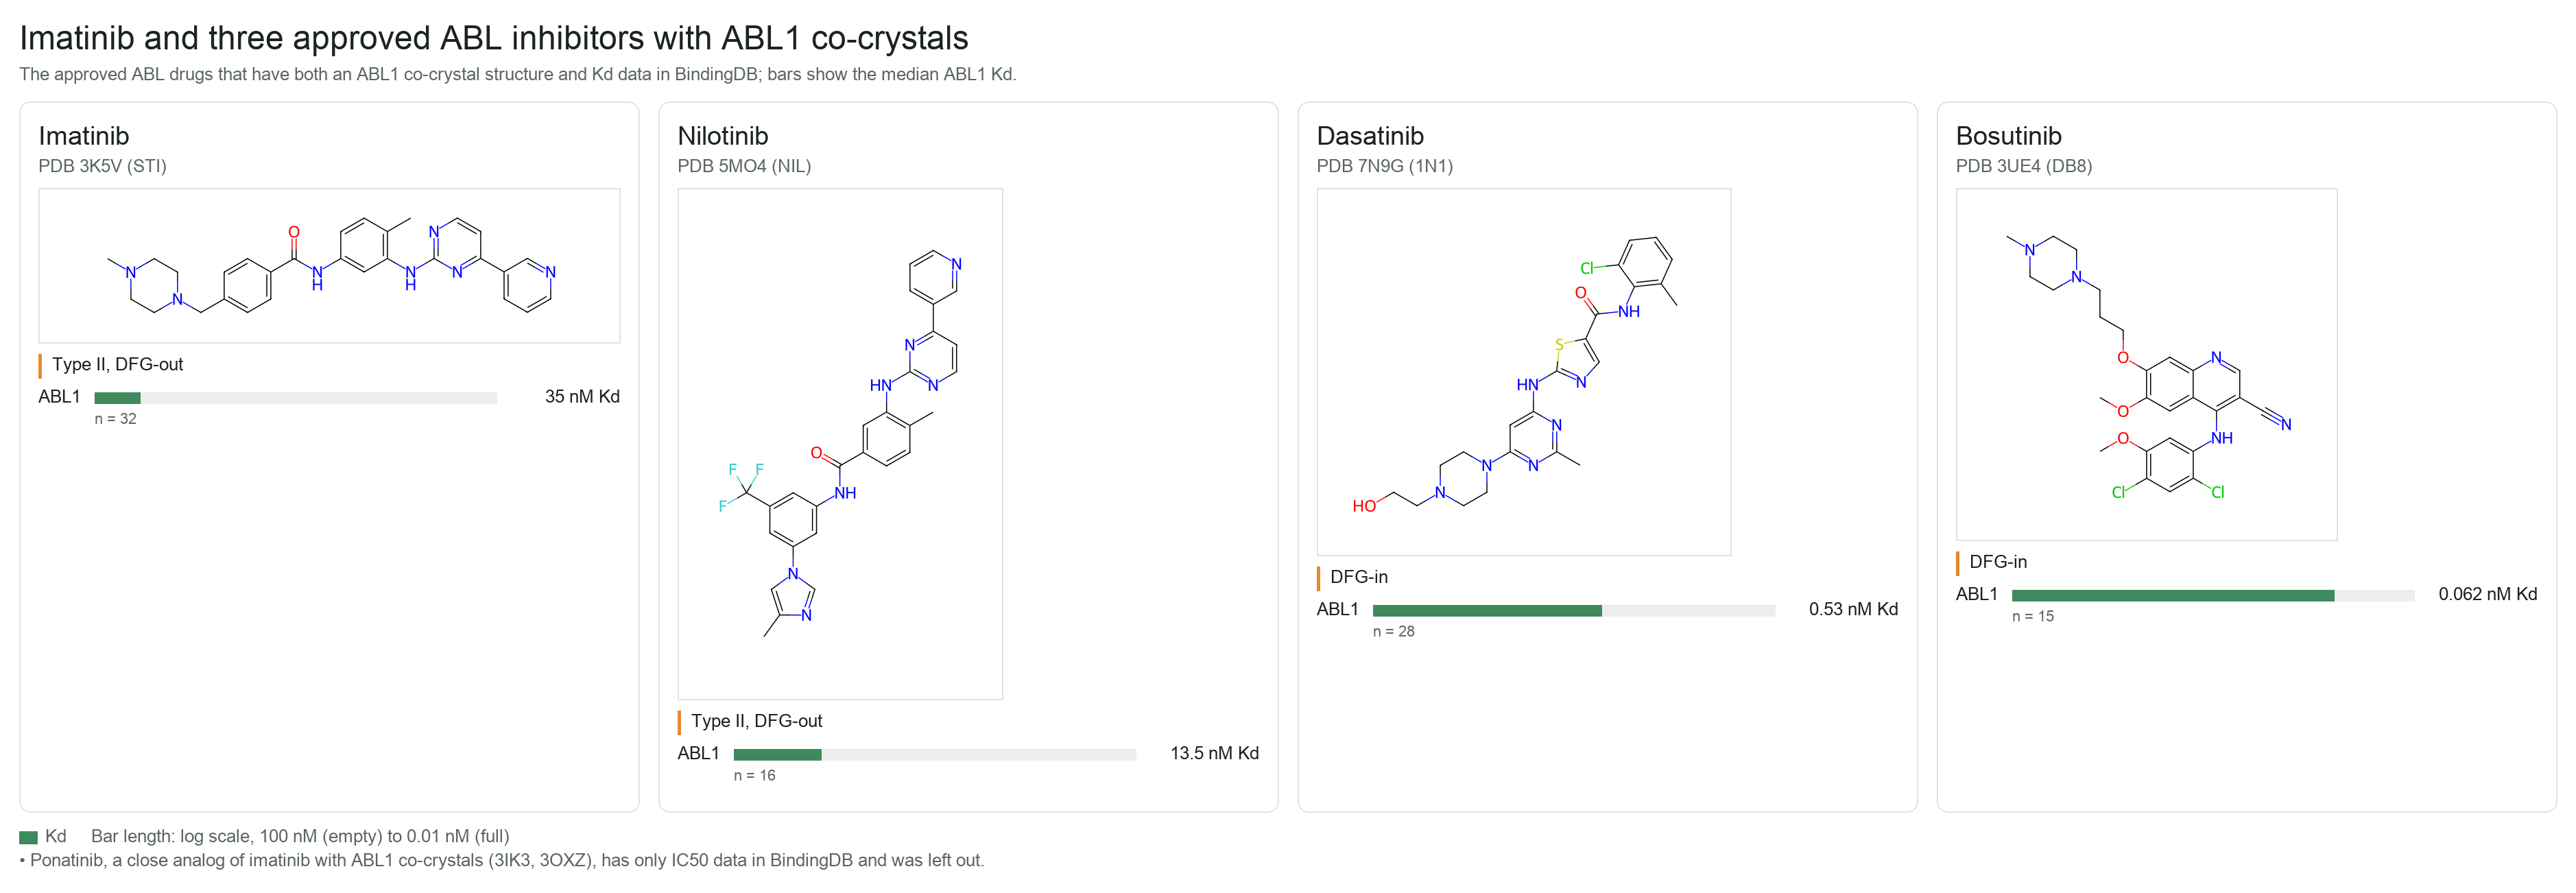

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'Imatinib and three approved ABL inhibitors with ABL1 co-crystals',
    'compounds': [
        {
            'smiles': 'CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1',
            'title': 'Imatinib',
            'subtitle': 'PDB 3K5V (STI)',
            'caption': 'Type II, DFG-out',
            'bars': [{'label': 'ABL1', 'value_nm': 35.0, 'type': 'Kd', 'note': 'n = 32'}],
        },
        {
            'smiles': 'Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F',
            'title': 'Nilotinib',
            'subtitle': 'PDB 5MO4 (NIL)',
            'caption': 'Type II, DFG-out',
            'bars': [{'label': 'ABL1', 'value_nm': 13.5, 'type': 'Kd', 'note': 'n = 16'}],
        },
        {
            'smiles': 'Cc1cccc(c1NC(=O)c2cnc(s2)Nc3cc(nc(n3)C)N4CCN(CC4)CCO)Cl',
            'title': 'Dasatinib',
            'subtitle': 'PDB 7N9G (1N1)',
            'caption': 'DFG-in',
            'bars': [{'label': 'ABL1', 'value_nm': 0.53, 'type': 'Kd', 'note': 'n = 28'}],
        },
        {
            'smiles': 'CN1CCN(CC1)CCCOc2cc3c(cc2OC)c(c(cn3)C#N)Nc4cc(c(cc4Cl)Cl)OC',
            'title': 'Bosutinib',
            'subtitle': 'PDB 3UE4 (DB8)',
            'caption': 'DFG-in',
            'bars': [{'label': 'ABL1', 'value_nm': 0.062, 'type': 'Kd', 'note': 'n = 15'}],
        },
    ],
    'columns': 4,
    'description': 'The approved ABL drugs that have both an ABL1 co-crystal structure and Kd data in BindingDB; bars show the median ABL1 Kd.',
    'notes': [
        'Ponatinib, a close analog of imatinib with ABL1 co-crystals (3IK3, 3OXZ), has only IC50 data in BindingDB and was left out.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

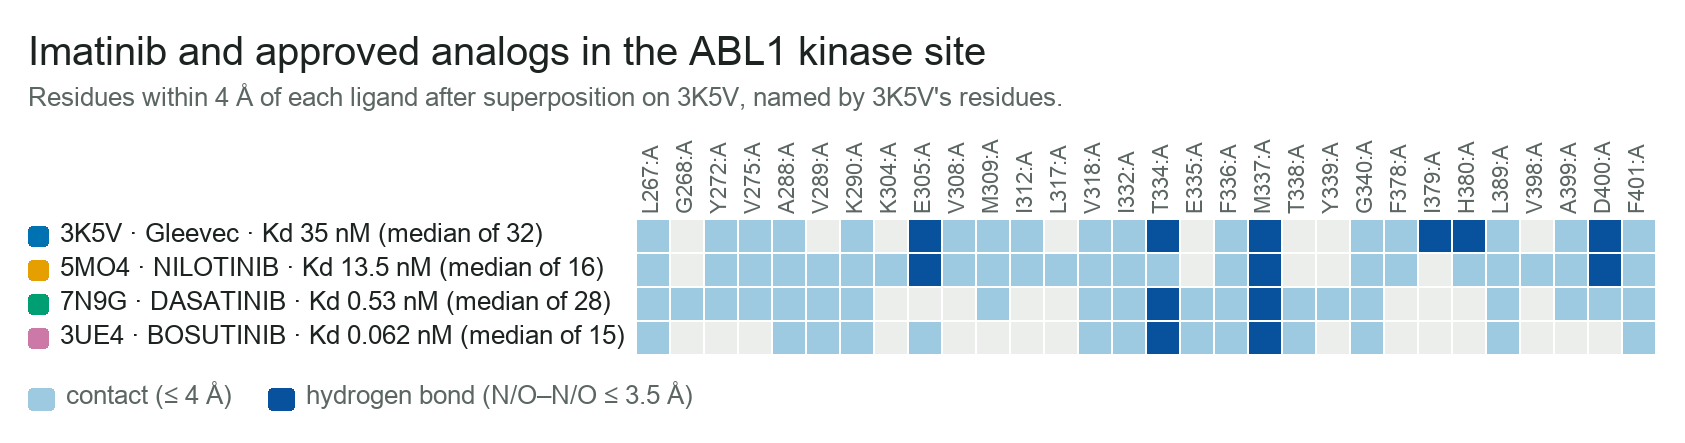

**Figure 2: Imatinib and approved analogs in the ABL1 kinase site (contacts).**

_Drawn by overlay_binding_site, whose call reruns above and draws it again._

**🧠 Assistant**

The 3D overlay is built and opened in your browser as a standalone viewer (this chat reaches the server without a viewer panel). The contact map and the structure grid are below.

**How the four were picked.** I resolved imatinib, nilotinib, dasatinib, bosutinib and ponatinib by name, then listed ABL1 (P00519) ligands that have PDB complexes and kept the approved drugs with both a co-crystal and a Ki/Kd measurement: imatinib (Gleevec, BDBM13530), nilotinib, dasatinib and bosutinib. Two notable exclusions: ponatinib is a structural relative of imatinib with 3IK3 and 3OXZ, but BindingDB carries only IC50 for it on ABL1; asciminib has a Kd and 5MO4/8SSN, but it binds the myristoyl pocket, not the ATP site, so it would not overlay meaningfully (5MO4 is shared with nilotinib, and I used nilotinib's ligand there). By the server's fingerprint similarity to imatinib, nilotinib is the only close analog (0.52); dasatinib and bosutinib fall below 0.3, so they are separate chemotypes hitting the same pocket, which is what makes the overlay interesting. The grid in the figure below could not align the four on a shared core: their largest common substructure has 7 atoms, below the 8-atom minimum, so they are drawn unaligned.

**What the overlay shows.** Four entries are superposed on 3K5V (imatinib, 1.74 A), with pocket RMSDs of 0.44 to 0.61 A (nilotinib 0.44, dasatinib 0.57, bosutinib 0.61), so the fits are clean. I chose 3K5V, 5MO4, 7N9G and 3UE4 explicitly, because the default choice of the best-resolution entry per compound gave imatinib 1IEP (2.10 A) as the reference instead.
- All four hydrogen bond to the hinge methionine M337 and T334, the gatekeeper threonine: the invariant anchor.
- The two type II ligands, imatinib and nilotinib, thread past the gatekeeper into the back pocket and pick up the DFG-out signature: H-bonds to E305 (the alpha-C glutamate) and D400 (the DFG aspartate). Imatinib adds H-bonds to I379 and H380 that nilotinib's trifluoromethyl-imidazole arm does not make. Nilotinib's pocket has no residue moved more than 2 A from imatinib's, so the two share one conformation.
- Dasatinib and bosutinib stop at the adenine pocket (M337 and T334) and make no back-pocket H-bonds (dasatinib has no others). Their DFG motif is in the active conformation: D400, F401 and G402 sit 4 to 6 A from their imatinib-bound positions, and the activation loop downstream (L403, L406) moves 13 to 26 A. Bosutinib's entry also has a displaced P-loop (G268 to G273 shifted 4 to 8 A), folding over its dichloro-methoxyaniline.

**On the affinities.** All four now have a Kd in BindingDB, so the comparison is like for like: bosutinib 0.062 nM (median of 15), dasatinib 0.53 nM (28), nilotinib 13.5 nM (16) and imatinib 35 nM (32). The two type I, DFG-in drugs bind about 70 to 500 times tighter than imatinib, and nilotinib is about 2.6-fold tighter than imatinib. Ki exists only for imatinib (25 nM, median of 6) and nilotinib (1 nM, a single measurement), and I would not rest the nilotinib-over-imatinib gain on that one value; Ki and Kd come from different assay formats and are not interchangeable. The viewer's Affinity menu switches the bars between Ki, Kd, IC50 and EC50.

**Try next.** Overlay the DFG-out set (imatinib, nilotinib, ponatinib's 3OXZ) to see what the IC50-only ponatinib adds, or compare these four against the T315I gatekeeper mutant with selectivity_matrix.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 8 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 6.2 — Imatinib and approved ABL inhibitors: co-crystals, binding-site overlay and affinities, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```